# Taller de Regresión y Regularización — Grupo B
## Predicción del precio de venta de apartamentos en Bogotá (Parte II)

**Curso:** Machine Learning Probabilístico · Especialización en Analítica Estratégica de Datos · Fundación Universitaria Konrad Lorenz
**Metodología:** CRISP-DM, fases 4 (Modelado) y 5 (Evaluación)

Este notebook continúa el Taller de EDA. Parte de la **base depurada** que dejó el EDA (`input/base_depurada.csv`, Habi + Metrocuadrado), a la que se le recalculan las variables de ubicación, y entrena cinco modelos de regresión para estimar `precio_venta`:

| # | Modelo | Para qué sirve en el taller |
|---|---|---|
| 1 | Regresión lineal múltiple (base) | Referencia con todas las variables candidatas |
| 2 | Selección hacia adelante (Forward) | Subconjunto construido agregando variables |
| 3 | Selección hacia atrás (Backward) | Subconjunto construido eliminando variables |
| 4 | Ridge (L2) | Encoge coeficientes sin eliminarlos |
| 5 | Lasso (L1) | Encoge y elimina variables automáticamente |

**Contenido**

1. Configuración
2. Carga y preparación de datos (y cambios respecto al EDA)
3. Selección y justificación de métricas
4. Partición entrenamiento / prueba
5. Preprocesamiento con `Pipeline`
6. Modelo base: regresión lineal múltiple, supuestos y multicolinealidad
7. Selección de variables: Forward y Backward
8. Regularización: Ridge
9. Regularización: Lasso
10. Comparación de modelos
11. Modelo final y exportación de artefactos para producción
12. Conclusiones y recomendaciones

**Estructura de carpetas**

```
modelado/
├── input/    base de datos y capas geográficas (entrada)
├── output/   modelo entrenado y artefactos (salida de este notebook)
├── src/      funciones compartidas con producción y con la app web
├── 01_modelado_regresion.ipynb   ← este notebook
└── 02_produccion.ipynb           notebook de puesta en producción
```

## 1. Configuración

Librerías, semilla global (`SEMILLA = 42`) para que todos los resultados sean reproducibles, y rutas relativas a la carpeta `modelado/`.

In [1]:
import json
import sys
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from scipy import stats
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge, lasso_path
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEMILLA = 42

# Carpeta `modelado/` (funciona si el notebook se abre desde `modelado/` o desde la raíz del repo)
DIR_MODELADO = Path.cwd() if (Path.cwd() / "input").exists() else Path.cwd() / "modelado"
DIR_INPUT = DIR_MODELADO / "input"
DIR_OUTPUT = DIR_MODELADO / "output"
DIR_OUTPUT.mkdir(exist_ok=True)
sys.path.insert(0, str(DIR_MODELADO.parent))   # para importar el paquete `modelado.src`

from modelado.src import preparacion as prep
from modelado.src.geo_features import GeoIndex, VARIABLES_CONTEO, VARIABLES_DISTANCIA

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 2. Carga y preparación de datos

### 2.1 Punto de partida
La base `input/base_depurada.csv` es la **salida depurada del Taller de EDA**: 10.224 apartamentos en venta (9.653 de Metrocuadrado y 571 de Habi) y 73 columnas. Ya viene:

- **Filtrada** con las reglas del EDA: solo apartamentos, coordenadas dentro de Bogotá, localidad conocida, precio entre \$70 M y \$30.000 M, área entre 15 y 1.000 m², precio por m² entre \$1,5 M y \$40 M, estrato de 1 a 6 y al menos un baño.
- **Sin duplicados** (se eliminaron antes de partir, para que el mismo anuncio no quede en *train* y en *test*).
- Con la **división 80/20** en la columna `conjunto` (8.179 *train* y 2.045 *test*).
- Con la **antigüedad armonizada a rangos** y **11 comodidades binarias** ya estructuradas (jacuzzi, tina, parqueadero cubierto, ascensor, gimnasio, piscina, conjunto cerrado, vigilancia, chimenea, balcón/terraza y depósito).

Por eso este notebook **no vuelve a filtrar**: solo lleva la base al formato de producción.

### 2.2 Qué se hace con la base depurada (y por qué)

| Lo que trae la base depurada | Qué se hace aquí | Por qué |
|---|---|---|
| Distancias y conteos de entorno ya calculados (red peatonal OSM y Haversine, radios de 200 m y 500 m) | Se **recalculan** desde la latitud/longitud con las capas de `input/` (estaciones, parques, puntos OSM y vías) usando `GeoIndex`: distancias **Haversine** y conteos a **500 m** | Producción debe aplicar *exactamente* la misma transformación a un apartamento nuevo, y `GeoIndex` es la función que usa la app. La distancia al parque se mide al **borde** más cercano (densificado cada 20 m). |
| `administracion` con los faltantes ya imputados (bandera `administracion_imputada`) | Los valores imputados **vuelven a ser faltantes** y se aplica el rango de validez de producción (\$20 mil – \$8 M); los imputa el `Pipeline` con la mediana de *train* | Evita fuga de información (*data leakage*) y reproduce lo que pasa en la app cuando el usuario deja el campo vacío. |
| `antiguedad_rango` con "A estrenar" y "Sin información" | "A estrenar" → "Nuevo / sobre planos"; "Sin información" → faltante (lo imputa el `Pipeline`) | Son los mismos rangos que ofrece el formulario de la app. |
| 11 comodidades binarias | Se usan **tal como vienen** | La base depurada no conserva el texto del anuncio, así que no se pueden extraer más comodidades. |
| División `conjunto` (train/test) | Se **respeta** | Mantiene la misma partición del EDA y hace comparables los resultados. |
| `estado`, `tipo_vendedor`, `barrio`, `precio_m2`, `log_precio_venta` | **No son candidatas** | `precio_m2` y `log_precio_venta` contienen el precio (fuga). `tipo_vendedor` identifica la fuente del anuncio, no el inmueble. `estado` repite la antigüedad y `barrio` tiene más de 1.200 categorías; ninguna la pediría el formulario. |

La lógica de ubicación y las reglas de armonización viven en `src/geo_features.py` y `src/preparacion.py`, que son **los mismos archivos que usan el notebook de producción y la aplicación web**.

In [2]:
# Base depurada del Taller de EDA (ya filtrada, sin duplicados y con la división train/test)
df_crudo = pd.read_csv(DIR_INPUT / "base_depurada.csv", low_memory=False)
print("Base depurada:", df_crudo.shape)
print(df_crudo["fuente"].value_counts().to_string())
print(df_crudo["conjunto"].value_counts().to_string())

Base depurada: (10224, 73)
fuente
metrocuadrado.com    9653
habi.co               571
conjunto
train    8179
test     2045


In [3]:
# Índice espacial: estaciones de TransMilenio, parques, equipamientos OSM y vías principales.
# Se construye desde los archivos crudos de input/ (tarda ~30 s por los 5.300 parques).
geo = GeoIndex.desde_archivos_crudos(DIR_INPUT)
print(f"Estaciones: {len(geo.capas['estaciones']['nombre'])} | Parques: {len(geo.capas['parques']['nombre']):,} | "
      f"Vías principales: {len(geo.capas['vias']['nombres'])}")
for cat, d in geo.capas["puntos"].items():
    print(f"  {cat:<22} {len(d['lat']):>6,} puntos")

Estaciones: 150 | Parques: 5,310 | Vías principales: 506
  hospitales_clinicas       555 puntos
  farmacias               1,490 puntos
  educacion               1,983 puntos
  comercio                2,553 puntos
  transporte              4,135 puntos
  recreacion              7,330 puntos
  religion                  741 puntos
  factores_negativos        633 puntos


In [4]:
from modelado.src.geo_features import BBOX_BOGOTA

# Comodidades binarias que trae la base depurada (ya estructuradas en el EDA): nombre -> etiqueta
COMODIDADES_BASE = {
    "tiene_jacuzzi": "Jacuzzi",
    "tiene_tina": "Tina",
    "parqueadero_cubierto": "Parqueadero cubierto",
    "tiene_ascensor": "Ascensor",
    "tiene_gimnasio": "Gimnasio",
    "tiene_piscina": "Piscina",
    "conjunto_cerrado": "Conjunto cerrado",
    "tiene_vigilancia": "Vigilancia / portería",
    "tiene_chimenea": "Chimenea",
    "tiene_balcon_terraza": "Balcón o terraza",
    "tiene_deposito": "Depósito",
}
ETIQUETAS = {**prep.ETIQUETAS, **COMODIDADES_BASE}


def preparar_base_depurada(df, geo):
    # La base ya viene filtrada y sin duplicados desde el EDA: aquí solo se lleva al formato de
    # producción y se recalculan las variables de ubicación con la MISMA función que usa la app.
    d = df.reset_index(drop=True)
    la0, la1, lo0, lo1 = BBOX_BOGOTA
    assert d["latitud"].between(la0, la1).all() and d["longitud"].between(lo0, lo1).all(), "Coordenadas fuera de Bogotá"
    assert not d.duplicated(subset="id").any(), "Hay anuncios repetidos"

    base = d[["fuente", "conjunto", "precio_venta", "area_m2", "habitaciones", "banos", "parqueaderos",
              "estrato", "latitud", "longitud"]].copy()
    # Administración: los valores que el EDA imputó vuelven a ser faltantes (los imputa el Pipeline
    # solo con train) y se aplica el mismo rango de validez que usa producción
    admin = d["administracion"].where(d["administracion_imputada"] == 0)
    base["administracion"] = prep.limpiar_administracion(admin)
    # Antigüedad: mismos rangos que el formulario ('A estrenar' -> 'Nuevo / sobre planos'; 'Sin información' -> faltante)
    base["antiguedad_rango"] = d["antiguedad_rango"].map(prep.armonizar_antiguedad)
    base["localidad"] = d["localidad"].str.strip().str.upper()
    base[list(COMODIDADES_BASE)] = d[list(COMODIDADES_BASE)].astype(int)

    # Variables de ubicación (Haversine) calculadas desde las capas de input/
    geo_vars = geo.calcular_variables(base["latitud"].to_numpy(), base["longitud"].to_numpy())
    return pd.concat([base, geo_vars], axis=1)


base = preparar_base_depurada(df_crudo, geo)
print("Base de modelado:", base.shape)
base.head(3)

Base de modelado: (10224, 48)


,fuente,conjunto,precio_venta,area_m2,habitaciones,banos,parqueaderos,estrato,latitud,longitud,administracion,antiguedad_rango,localidad,tiene_jacuzzi,tiene_tina,parqueadero_cubierto,tiene_ascensor,tiene_gimnasio,tiene_piscina,conjunto_cerrado,tiene_vigilancia,tiene_chimenea,tiene_balcon_terraza,tiene_deposito,estacion,dist_estacion_m,parque,dist_parque_m,dist_hospitales_clinicas_m,hospitales_clinicas_500m,dist_farmacias_m,farmacias_500m,dist_educacion_m,educacion_500m,dist_comercio_m,comercio_500m,dist_transporte_m,transporte_500m,dist_recreacion_m,recreacion_500m,dist_religion_m,religion_500m,dist_factores_negativos_m,factores_negativos_500m,via_principal_cercana,tipo_via_principal_cercana,dist_via_principal_m,vias_principales_500m
0,habi.co,train,"580,000,000.000",88.000,2,2,1,6,4.681,-74.054,"980,101.000",Más de 20 años,CHAPINERO,0,0,0,1,0,0,0,1,0,0,0,Calle 100 - Marketmedios,599.900,CHICO NORTE,56.900,157.600,4,261.800,10,405.400,2,313.800,8,363.200,16,164.200,8,208.500,2,986.700,0,Avenida Calle 94,secondary,34.500,7
1,habi.co,train,"519,900,000.000",63.000,2,2,1,4,4.742,-74.068,"314,555.000",Entre 5 y 10 años,SUBA,0,0,1,1,0,0,1,1,0,0,1,21 Ángeles,"1,614.800",Urbanizacion CasaBlanca,18.900,433.300,1,416.000,3,459.000,1,371.600,4,78.500,11,128.000,15,808.400,0,"1,486.900",0,Avenida Calle 153,primary,238.700,2
2,habi.co,train,"420,000,000.000",74.000,2,2,1,4,4.666,-74.107,"308,000.000",Entre 10 y 20 años,ENGATIVA,0,0,1,1,0,0,0,1,0,0,0,Avenida Rojas - UNISALESIANA,506.300,URBANIZACION NORMANDIA I SECTOR,175.700,453.100,1,127.000,4,381.600,3,406.000,1,135.600,8,188.200,11,380.700,1,"1,101.800",0,Avenida Carrera 70,secondary,22.600,4


### 2.3 Variables candidatas

Cada variable original es un **bloque**: las variables categóricas (antigüedad, localidad, tipo de vía) generan varias dummies, pero se tratan como una sola variable en la selección (ver sección 7).

In [5]:
VARS_LOG, VARS_NUM, VARS_CAT = prep.VARS_LOG, prep.VARS_NUM, prep.VARS_CAT
VARS_BIN = list(COMODIDADES_BASE)                      # las 11 comodidades de la base depurada
VARIABLES = VARS_LOG + VARS_NUM + VARS_BIN + VARS_CAT
OBJETIVO = prep.OBJETIVO

resumen_vars = pd.DataFrame({
    "Grupo": ["Numéricas con cola larga (log1p)", "Numéricas", "Comodidades (binarias)", "Categóricas (one-hot)"],
    "Cantidad": [len(VARS_LOG), len(VARS_NUM), len(VARS_BIN), len(VARS_CAT)],
    "Variables": [", ".join(v) for v in (VARS_LOG, VARS_NUM, VARS_BIN, VARS_CAT)],
})
print("Total de variables candidatas:", len(VARIABLES))
with pd.option_context("display.max_colwidth", None):
    display(resumen_vars)

Total de variables candidatas: 42


,Grupo,Cantidad,Variables
0,Numéricas con cola larga (log1p),13,"area_m2, administracion, dist_estacion_m, dist_parque_m, dist_hospitales_clinicas_m, dist_farmacias_m, dist_educacion_m, dist_comercio_m, dist_transporte_m, dist_recreacion_m, dist_religion_m, dist_factores_negativos_m, dist_via_principal_m"
1,Numéricas,15,"habitaciones, banos, parqueaderos, estrato, latitud, longitud, hospitales_clinicas_500m, farmacias_500m, educacion_500m, comercio_500m, transporte_500m, recreacion_500m, religion_500m, factores_negativos_500m, vias_principales_500m"
2,Comodidades (binarias),11,"tiene_jacuzzi, tiene_tina, parqueadero_cubierto, tiene_ascensor, tiene_gimnasio, tiene_piscina, conjunto_cerrado, tiene_vigilancia, tiene_chimenea, tiene_balcon_terraza, tiene_deposito"
3,Categóricas (one-hot),3,"antiguedad_rango, localidad, tipo_via_principal_cercana"


In [6]:
# Nulos que quedan (los resuelve el Pipeline con imputación ajustada solo en train)
nulos = base[VARIABLES].isna().mean().mul(100).round(2)
print("Variables con nulos (%):")
print(nulos[nulos > 0].to_string())

# Antigüedad armonizada a rangos y frecuencia de cada comodidad por fuente
display(base["antiguedad_rango"].value_counts(dropna=False).to_frame("anuncios"))
display(base.groupby("fuente")[VARS_BIN].mean().T.mul(100).round(1).rename_axis("% de anuncios con la comodidad"))

Variables con nulos (%):
administracion     14.210
antiguedad_rango    0.480


,anuncios
antiguedad_rango,
Más de 20 años,3788
Entre 10 y 20 años,2317
Entre 0 y 5 años,1872
Entre 5 y 10 años,1377
Remodelado,621
Nuevo / sobre planos,200
NaN,49


fuente,habi.co,metrocuadrado.com
% de anuncios con la comodidad,,
tiene_jacuzzi,0.200,5.500
tiene_tina,0.000,18.500
parqueadero_cubierto,7.900,34.100
tiene_ascensor,58.700,73.500
tiene_gimnasio,14.700,43.400
tiene_piscina,3.700,15.100
conjunto_cerrado,71.800,50.600
tiene_vigilancia,80.600,74.400
tiene_chimenea,0.000,40.800


**Lectura.** Solo quedan nulos en `administracion` (14,2 %: los que el EDA había imputado más los que salen del rango válido) y en `antiguedad_rango` (0,5 %, los "Sin información"). En Habi casi todas las comodidades aparecen con menor frecuencia que en Metrocuadrado (tina 0 % frente a 18 %, depósito 6 % frente a 69 %), porque allí se derivaron del texto libre de la descripción; es una limitación de la fuente que se retoma en las conclusiones.

### 2.4 Variable objetivo

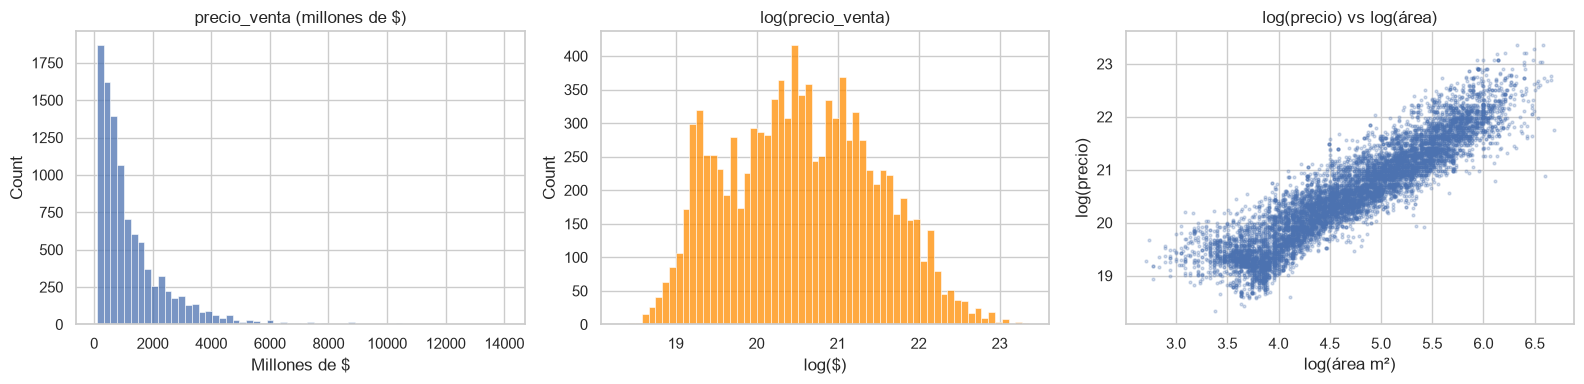

Asimetría precio: 2.64 | Asimetría log(precio): 0.14
Precio mediano: $830 M | medio: $1,282 M


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(base[OBJETIVO] / 1e6, bins=60, ax=ax[0])
ax[0].set(title="precio_venta (millones de $)", xlabel="Millones de $")
sns.histplot(np.log(base[OBJETIVO]), bins=60, ax=ax[1], color="darkorange")
ax[1].set(title="log(precio_venta)", xlabel="log($)")
ax[2].scatter(np.log(base["area_m2"]), np.log(base[OBJETIVO]), s=4, alpha=0.25)
ax[2].set(title="log(precio) vs log(área)", xlabel="log(área m²)", ylabel="log(precio)")
plt.tight_layout(); plt.show()
print(f"Asimetría precio: {base[OBJETIVO].skew():.2f} | Asimetría log(precio): {np.log(base[OBJETIVO]).skew():.2f}")
print(f"Precio mediano: ${base[OBJETIVO].median()/1e6:,.0f} M | medio: ${base[OBJETIVO].mean()/1e6:,.0f} M")

El precio tiene una cola derecha muy larga; su logaritmo es casi simétrico y la relación con el logaritmo del área es prácticamente lineal. Por eso **se modela `log(precio_venta)`** (como se anticipó en el EDA). Un modelo lineal en logaritmos equivale a efectos *porcentuales*: "un baño más aumenta el precio en X %", que es como razona el mercado inmobiliario.

El logaritmo se aplica con `TransformedTargetRegressor`: el modelo se ajusta en escala logarítmica pero `predict()` devuelve **pesos**, de modo que todas las métricas se reportan en pesos.

## 3. Selección y justificación de métricas

**¿Para quién es el modelo?** Para un **iBuyer / asesor inmobiliario tipo Habi**, que usa la predicción como precio de referencia para hacer una oferta de compra o para orientar a un propietario sobre el precio de publicación. Para este usuario:

- Sobrevalorar un inmueble significa **pagar de más** y quedarse con un activo que no se vende (pérdida directa de capital).
- Subvalorarlo significa **perder el negocio** frente a la competencia (costo de oportunidad).
- Un error de \$100 M pesa distinto en un apartamento de \$300 M (33 %) que en uno de \$3.000 M (3 %).

| Métrica | Rol | Justificación |
|---|---|---|
| **MAE** (en pesos) | **Principal** | Es el error típico por inmueble y se comunica sin tecnicismos: *"en promedio nos equivocamos por \$X millones"*. No eleva al cuadrado, así que no queda dominado por unos pocos apartamentos de lujo: describe el error del inmueble *típico*, que es el grueso del negocio. |
| **RMSE** (en pesos) | Complementaria de riesgo | Eleva al cuadrado, luego **castiga los errores grandes**. Para un iBuyer un solo error enorme en un apartamento costoso puede borrar el margen de muchas operaciones buenas, por eso se vigila la brecha RMSE – MAE: si es grande, hay errores extremos. |
| **R²** (en pesos) | Complementaria | Indica qué proporción de la variabilidad del precio explica el modelo. Sirve para comparar modelos, pero no dice cuánto dinero se pierde; acompaña, no reemplaza, a MAE y RMSE. |
| **MAPE** (%) | Apoyo | Error porcentual medio; permite comparar el desempeño entre segmentos de precio distintos. |

**Escala de reporte.** Aunque se entrena sobre `log(precio)`, todas las métricas se calculan **en pesos** después de aplicar la exponencial, porque es la unidad que entiende el negocio. (La exponencial de una predicción en logaritmos estima la *mediana* condicional del precio, lo que es coherente con usar MAE como métrica principal.)

**Criterio de selección de hiperparámetros:** MAE en pesos con validación cruzada de 5 pliegues sobre *train*. El conjunto de prueba se usa **una sola vez**, al final, en la tabla comparativa.

In [8]:
def metricas(y_real, y_pred):
    # Métricas en pesos (MAE y RMSE en millones para facilitar la lectura)
    return {
        "MAE (M$)": mean_absolute_error(y_real, y_pred) / 1e6,
        "RMSE (M$)": root_mean_squared_error(y_real, y_pred) / 1e6,
        "R²": r2_score(y_real, y_pred),
        "MAPE (%)": np.mean(np.abs(y_pred - y_real) / y_real) * 100,
    }


def evaluar(modelo, nombre):
    # Evalúa un modelo ya ajustado en train y en test; devuelve dos filas para la tabla comparativa
    filas = []
    for conjunto, X_, y_ in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        filas.append({"Modelo": nombre, "Conjunto": conjunto, **metricas(y_, modelo.predict(X_))})
    return filas

## 4. Partición entrenamiento / prueba

Se usa la división **80 % entrenamiento – 20 % prueba que dejó el Taller de EDA** (columna `conjunto`), de modo que el modelado trabaja sobre la misma partición. Los duplicados se eliminaron **antes** de partir para que el mismo anuncio no quede a ambos lados. Todo lo que "aprende" de los datos (medianas de imputación, medias y desviaciones del escalado, categorías, selección de variables, α) se ajusta únicamente con *train*.

In [9]:
X = base[VARIABLES]
y = base[OBJETIVO]
es_train = base["conjunto"].eq("train")                 # división 80/20 definida en el Taller de EDA
X_train, X_test = X[es_train], X[~es_train]
y_train, y_test = y[es_train], y[~es_train]
print(f"Train: {X_train.shape} | Test: {X_test.shape} | % test: {len(X_test) / len(X) * 100:.1f}")
print(f"Precio mediano train: ${y_train.median()/1e6:,.0f} M | test: ${y_test.median()/1e6:,.0f} M")

# Viviendas de referencia (solo train) para inferir la localidad de una dirección nueva en producción
ref = X_train.dropna(subset=["localidad"])
geo.registrar_referencia_localidad(ref["latitud"], ref["longitud"], ref["localidad"])

Train: (8179, 42) | Test: (2045, 42) | % test: 20.0
Precio mediano train: $830 M | test: $828 M


## 5. Preprocesamiento con `Pipeline`

Un `ColumnTransformer` aplica a cada grupo de variables su tratamiento, y queda encadenado con el estimador en un `Pipeline`:

| Grupo | Imputación | Transformación | Escalado |
|---|---|---|---|
| Numéricas con cola larga (área, administración, distancias) | Mediana | `log1p` | `StandardScaler` |
| Numéricas (habitaciones, baños, estrato, conteos…) | Mediana | — | `StandardScaler` |
| Comodidades binarias | Moda | — | `StandardScaler` |
| Categóricas (antigüedad, localidad, tipo de vía) | Moda | One-hot (sin la primera categoría; categorías con < 30 casos se agrupan) | `StandardScaler` |

Se estandarizan **todas** las columnas (también las dummies) porque Ridge y Lasso penalizan el tamaño de los coeficientes y este depende de la escala. En la regresión lineal sin penalización el escalado no cambia las predicciones, así que usar el mismo preprocesador en los cinco modelos hace la comparación justa.

In [10]:
def crear_preprocesador(variables):
    # ColumnTransformer para el subconjunto de variables indicado (cada variable original = un bloque)
    v_log = [v for v in variables if v in VARS_LOG]
    v_num = [v for v in variables if v in VARS_NUM]
    v_bin = [v for v in variables if v in VARS_BIN]
    v_cat = [v for v in variables if v in VARS_CAT]
    pasos = []
    if v_log:
        pasos.append(("log", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("escalar", StandardScaler()),
        ]), v_log))
    if v_num:
        pasos.append(("num", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), v_num))
    if v_bin:
        pasos.append(("bin", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("escalar", StandardScaler()),
        ]), v_bin))
    if v_cat:
        pasos.append(("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", min_frequency=30,
                                     handle_unknown="infrequent_if_exist", sparse_output=False)),
            ("escalar", StandardScaler()),
        ]), v_cat))
    return ColumnTransformer(pasos, verbose_feature_names_out=False)


def crear_modelo(estimador, variables=VARIABLES):
    # Pipeline completo: preprocesamiento + estimador, entrenado sobre log(precio) y que predice en pesos
    pipeline = Pipeline([("prep", crear_preprocesador(variables)), ("modelo", estimador)])
    return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)


CV = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # mismos pliegues para todos los modelos

In [11]:
# Matriz de diseño de train (solo para diagnósticos, selección de variables y trayectorias).
# El preprocesador se ajusta únicamente con train.
prep_train = crear_preprocesador(VARIABLES).fit(X_train)
columnas = list(prep_train.get_feature_names_out())
Xt_train = pd.DataFrame(prep_train.transform(X_train), columns=columnas, index=X_train.index)
ylog_train = np.log(y_train)

# Bloques: variable original -> columnas que genera en la matriz de diseño
BLOQUES = {v: ([c for c in columnas if c.startswith(v + "_")] if v in VARS_CAT else [v]) for v in VARIABLES}
assert sum(len(c) for c in BLOQUES.values()) == len(columnas)
print(f"{len(VARIABLES)} variables originales -> {len(columnas)} columnas en la matriz de diseño")
for v in VARS_CAT:
    print(f"  {v}: {len(BLOQUES[v])} dummies")

42 variables originales -> 62 columnas en la matriz de diseño
  antiguedad_rango: 5 dummies
  localidad: 16 dummies
  tipo_via_principal_cercana: 2 dummies


## 6. Modelo base: regresión lineal múltiple

Modelo de referencia con **todas** las variables candidatas. Contra él se comparan los demás.

In [12]:
resultados = []          # filas de la tabla comparativa
modelos = {}             # modelos ajustados

modelos["Base (OLS)"] = crear_modelo(LinearRegression()).fit(X_train, y_train)
resultados += evaluar(modelos["Base (OLS)"], "Base (OLS)")
pd.DataFrame(resultados).set_index(["Modelo", "Conjunto"])

MAE (M$)  RMSE (M$)    R²  MAPE (%)
Modelo     Conjunto                                     
Base (OLS) Train      237.152    511.934 0.846    16.139
           Test       241.037    512.132 0.859    15.912

In [13]:
# Mismo modelo con statsmodels (sobre la matriz de diseño de train) para obtener inferencia: errores estándar y p-valores
ols = sm.OLS(ylog_train, sm.add_constant(Xt_train)).fit()
print(f"R² (log) = {ols.rsquared:.4f} | R² ajustado = {ols.rsquared_adj:.4f} | AIC = {ols.aic:,.0f} | BIC = {ols.bic:,.0f}")

coef_base = pd.DataFrame({"coef": ols.params, "error_std": ols.bse, "p_valor": ols.pvalues}).drop("const")
coef_base["efecto_%_por_1_desv"] = (np.exp(coef_base["coef"]) - 1) * 100
coef_base = coef_base.reindex(coef_base["coef"].abs().sort_values(ascending=False).index)
print(f"Coeficientes no significativos al 5 %: {(coef_base['p_valor'] > 0.05).sum()} de {len(coef_base)}")
coef_base.head(15)

R² (log) = 0.9474 | R² ajustado = 0.9470 | AIC = -2,300 | BIC = -1,859
Coeficientes no significativos al 5 %: 20 de 62


,coef,error_std,p_valor,efecto_%_por_1_desv
area_m2,0.581,0.007,0.000,78.787
longitud,0.161,0.010,0.000,17.438
antiguedad_rango_Más de 20 años,-0.146,0.004,0.000,-13.552
estrato,0.110,0.005,0.000,11.662
latitud,-0.109,0.007,0.000,-10.337
parqueaderos,0.102,0.005,0.000,10.757
antiguedad_rango_Entre 10 y 20 años,-0.072,0.003,0.000,-6.964
administracion,0.061,0.005,0.000,6.302
localidad_USME,-0.061,0.004,0.000,-5.880
banos,0.041,0.005,0.000,4.188


**Lectura del modelo base.**

- En escala logarítmica explica el **94,7 %** de la variabilidad (R² ajustado 0,947). En pesos, el R² es 0,85 en *train*: el error crece al deshacer el logaritmo porque los apartamentos costosos pesan más.
- Los coeficientes están sobre variables estandarizadas, así que son comparables entre sí. El **área** domina (+79 % de precio por cada desviación estándar de log-área), seguida de la **ubicación** (longitud +17 %, latitud −10 %, localidad), la **antigüedad** (más de 20 años: −14 %), el **estrato** (+12 %) y los **parqueaderos** (+11 %).
- `habitaciones` tiene signo negativo: a igual área, más habitaciones significa espacios más pequeños. No es un error, es el efecto *condicional* al área, y es una primera señal de que los coeficientes de variables correlacionadas no se pueden leer de forma aislada.
- **20 de los 62 coeficientes no son significativos al 5 %**: el modelo base carga variables que no aportan, lo que motiva la selección de variables (sección 7) y Lasso (sección 9).

### 6.1 Revisión de supuestos

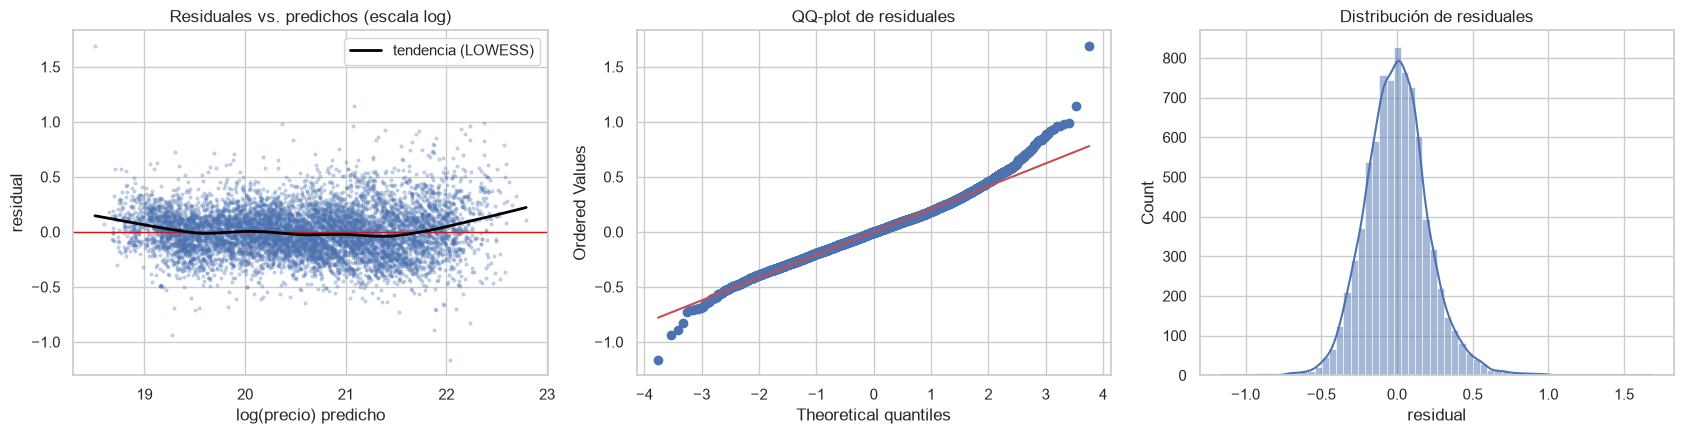

Jarque-Bera (normalidad): estadístico = 1,161, p = 6.96e-253 | asimetría = 0.36, curtosis = 4.70
Breusch-Pagan (homocedasticidad): estadístico = 513, p = 3.36e-72
Desviación estándar del residual: 0.209 (≈ ±23 % en pesos)
Residuales con |z| > 3: 0.84 % (esperado bajo normalidad: 0.27 %)


In [14]:
pred_log = ols.fittedvalues
resid = ols.resid

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(pred_log, resid, s=4, alpha=0.25)
ax[0].axhline(0, color="red", lw=1)
suav = sm.nonparametric.lowess(resid, pred_log, frac=0.3)
ax[0].plot(suav[:, 0], suav[:, 1], color="black", lw=2, label="tendencia (LOWESS)")
ax[0].set(title="Residuales vs. predichos (escala log)", xlabel="log(precio) predicho", ylabel="residual"); ax[0].legend()
stats.probplot(resid, dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot de residuales")
sns.histplot(resid, bins=60, kde=True, ax=ax[2]); ax[2].set(title="Distribución de residuales", xlabel="residual")
plt.tight_layout(); plt.show()

jb, jb_p = stats.jarque_bera(resid)
bp, bp_p, _, _ = het_breuschpagan(resid, ols.model.exog)
print(f"Jarque-Bera (normalidad): estadístico = {jb:,.0f}, p = {jb_p:.3g} | asimetría = {stats.skew(resid):.2f}, curtosis = {stats.kurtosis(resid, fisher=False):.2f}")
print(f"Breusch-Pagan (homocedasticidad): estadístico = {bp:,.0f}, p = {bp_p:.3g}")
print(f"Desviación estándar del residual: {resid.std():.3f} (≈ ±{(np.exp(resid.std())-1)*100:.0f} % en pesos)")
print(f"Residuales con |z| > 3: {(np.abs(resid / resid.std()) > 3).mean()*100:.2f} % (esperado bajo normalidad: 0.27 %)")

**¿Qué dicen los supuestos?**

- **Linealidad:** la tendencia LOWESS de los residuales se mantiene pegada a cero en casi todo el rango; solo se curva hacia arriba en los dos extremos (apartamentos muy económicos y muy costosos, donde el modelo tiende a quedarse corto). La especificación log-log es razonable.
- **Homocedasticidad:** Breusch-Pagan la rechaza (p ≈ 10⁻⁷²). La dispersión no es constante: hay más varianza en los extremos de precio. Consecuencia: los errores estándar y p-valores de OLS son optimistas, por lo que **no conviene usar el p-valor como criterio de selección** (se usa BIC).
- **Normalidad:** los residuales son casi simétricos (asimetría 0,36) pero con **colas pesadas** (curtosis 4,7; 0,84 % de residuales con |z| > 3 frente al 0,27 % esperado). Jarque-Bera rechaza normalidad, algo casi inevitable con 8.000 datos. Con este tamaño de muestra los coeficientes siguen siendo confiables (teorema central del límite); lo que se afecta son los intervalos de predicción, y por eso la banda de incertidumbre de producción se construye con **cuantiles empíricos** del error y no con la fórmula normal.
- La desviación estándar del residual es 0,21 en logaritmos: el modelo acierta el precio con un error típico de ±23 %.

En resumen: los supuestos se cumplen lo suficiente para **predecir**, pero no para hacer inferencia fina coeficiente por coeficiente.

### 6.2 Multicolinealidad (VIF)

El VIF de una columna mide cuánto se infla la varianza de su coeficiente por estar correlacionada con las demás (VIF = 1/(1 − R²ⱼ)). Regla habitual: > 5 moderado, > 10 alto.

Columnas con VIF > 10: 6 | con VIF entre 5 y 10: 4 | de 62
localidad_USAQUEN     17.600
longitud              17.500
localidad_CHAPINERO   12.900
localidad_SUBA        10.600
area_m2               10.200
latitud               10.100
localidad_FONTIBON     6.700
localidad_BOSA         6.500
localidad_KENNEDY      5.600
banos                  5.100
parqueaderos           4.800
estrato                4.500


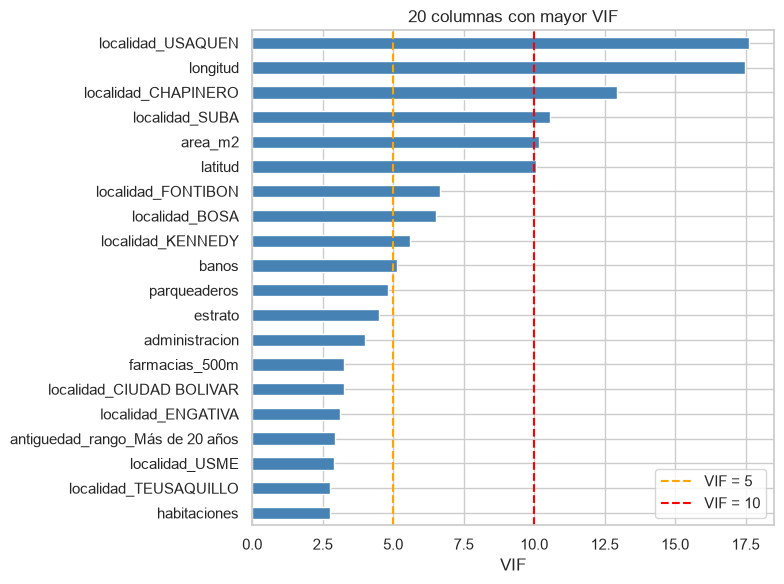

Pares de columnas más correlacionados:
area_m2         banos            0.880
                parqueaderos     0.850
banos           parqueaderos     0.800
area_m2         administracion   0.790
administracion  parqueaderos     0.760
                estrato          0.750
parqueaderos    estrato          0.720
administracion  banos            0.720
area_m2         estrato          0.710
                habitaciones     0.680


In [15]:
# VIF = diagonal de la inversa de la matriz de correlaciones de la matriz de diseño (equivale a 1/(1-R²_j))
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Xt_train.values, rowvar=False))), index=columnas).sort_values(ascending=False)
print(f"Columnas con VIF > 10: {(vif > 10).sum()} | con VIF entre 5 y 10: {((vif > 5) & (vif <= 10)).sum()} | de {len(vif)}")
print(vif.head(12).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
vif.head(20).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.axvline(5, color="orange", ls="--", label="VIF = 5"); ax.axvline(10, color="red", ls="--", label="VIF = 10")
ax.set(title="20 columnas con mayor VIF", xlabel="VIF"); ax.legend(); plt.tight_layout(); plt.show()

# Correlaciones más altas entre pares de columnas
corr = Xt_train.corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().sort_values(ascending=False)
print("Pares de columnas más correlacionados:")
print(pares.head(10).round(2).to_string())

**¿Qué dice el VIF sobre la estabilidad de los coeficientes?**

- **6 columnas superan VIF 10** y otras 4 están entre 5 y 10. Hay dos focos:
  1. **Ubicación:** `localidad_USAQUEN` (17,6), `longitud` (17,5), `localidad_CHAPINERO` (12,9), `localidad_SUBA` (10,6) y `latitud` (10,1). Es esperable: la localidad *es* una función de la latitud y la longitud; las tres describen el mismo fenómeno.
  2. **Tamaño del inmueble:** `area_m2` (10,2), `banos` (5,1), `parqueaderos` (4,8). El área se correlaciona 0,88 con baños y 0,85 con parqueaderos: los apartamentos grandes tienen más de todo.
- Las comodidades y las variables de entorno tienen VIF bajos (< 5): están correlacionadas entre sí, pero no al punto de ser redundantes.
- **Implicación:** los coeficientes de esos dos grupos son **inestables** — su magnitud (e incluso su signo, como en Usaquén: −4 % pese a ser una zona costosa) depende de qué otras variables estén en el modelo, porque el efecto se reparte entre ellas. Las **predicciones no se ven afectadas** (la combinación sí está bien estimada), pero no se debe interpretar, por ejemplo, el coeficiente de una localidad como "el valor de vivir allí". Ridge ataca precisamente este problema.

## 7. Selección de variables: Forward y Backward

**Criterio de parada: BIC** (criterio de información bayesiano), calculado sobre *train* en escala logarítmica:

$$\text{BIC} = n\,\ln\!\left(\frac{\text{RSS}}{n}\right) + k\,\ln(n)$$

- Se eligió BIC en lugar del p-valor porque los p-valores individuales son poco confiables cuando hay multicolinealidad y heterocedasticidad (sección 6), y porque con *n* ≈ 8.000 casi cualquier efecto resulta "significativo".
- Se eligió BIC sobre AIC porque penaliza más cada parámetro adicional (ln *n* ≈ 9 frente a 2): favorece modelos **parsimoniosos**, que es lo que se busca al seleccionar variables para un formulario de producción.
- **Forward:** parte del modelo vacío y agrega, en cada paso, el bloque que más reduce el BIC. **Se detiene cuando ningún bloque restante lo reduce.**
- **Backward:** parte del modelo completo y elimina, en cada paso, el bloque cuya salida más reduce el BIC. **Se detiene cuando eliminar cualquier bloque lo aumenta.**

**Decisión sobre las variables categóricas (antigüedad en rangos, localidad, tipo de vía): se tratan como bloque.** Todas las dummies de una variable entran o salen juntas. Razones:

1. Una dummy suelta solo tiene sentido frente a la categoría de referencia: si se saca "Entre 5 y 10 años" y se deja "Más de 20 años", la referencia pasa a ser una mezcla de categorías difícil de interpretar.
2. En producción el usuario diligencia **la variable completa** (un solo campo "Antigüedad"), no dummies individuales.
3. El BIC ya cobra el costo del bloque: una variable con *m* dummies paga *m*·ln(*n*), así que solo entra si en conjunto aporta.

In [16]:
# Para evaluar miles de subconjuntos rápidamente se usan las ecuaciones normales con la matriz de Gram
# precalculada: RSS(S) = y'y - c_S' (G_SS)^-1 c_S. Es exactamente el mismo OLS, sin reajustar cada vez.
n_train = len(ylog_train)
A = np.column_stack([np.ones(n_train), Xt_train.values])     # intercepto + columnas
G, c, yty = A.T @ A, A.T @ ylog_train.values, float(ylog_train.values @ ylog_train.values)
POS = {col: i + 1 for i, col in enumerate(columnas)}          # posición de cada columna en A


def bic_subconjunto(variables_sel):
    # BIC del modelo OLS que usa los bloques indicados (más el intercepto)
    idx = [0] + [POS[col] for v in variables_sel for col in BLOQUES[v]]
    beta = np.linalg.lstsq(G[np.ix_(idx, idx)], c[idx], rcond=None)[0]
    rss = yty - c[idx] @ beta
    return n_train * np.log(rss / n_train) + len(idx) * np.log(n_train)


def seleccion_forward():
    seleccion, restantes, historial = [], list(VARIABLES), []
    bic_actual = bic_subconjunto([])
    while restantes:
        candidatos = {v: bic_subconjunto(seleccion + [v]) for v in restantes}
        mejor = min(candidatos, key=candidatos.get)
        if candidatos[mejor] >= bic_actual:          # criterio de parada: ningún bloque mejora el BIC
            break
        seleccion.append(mejor); restantes.remove(mejor); bic_actual = candidatos[mejor]
        historial.append({"paso": len(seleccion), "variable": mejor, "BIC": bic_actual})
    return seleccion, pd.DataFrame(historial)


def seleccion_backward():
    seleccion, historial = list(VARIABLES), []
    bic_actual = bic_subconjunto(seleccion)
    while len(seleccion) > 1:
        candidatos = {v: bic_subconjunto([s for s in seleccion if s != v]) for v in seleccion}
        peor = min(candidatos, key=candidatos.get)
        if candidatos[peor] >= bic_actual:           # criterio de parada: quitar cualquier bloque empeora el BIC
            break
        seleccion.remove(peor); bic_actual = candidatos[peor]
        historial.append({"paso": len(historial) + 1, "variable_eliminada": peor, "BIC": bic_actual})
    return seleccion, pd.DataFrame(historial)


vars_forward, hist_forward = seleccion_forward()
vars_backward, hist_backward = seleccion_backward()
print(f"BIC modelo vacío: {bic_subconjunto([]):,.0f} | BIC modelo completo: {bic_subconjunto(VARIABLES):,.0f}")
print(f"Forward : {len(vars_forward)} variables | BIC final = {hist_forward['BIC'].iloc[-1]:,.0f}")
print(f"Backward: {len(vars_backward)} variables | BIC final = {hist_backward['BIC'].iloc[-1]:,.0f}")

BIC modelo vacío: -1,535 | BIC modelo completo: -25,070
Forward : 19 variables | BIC final = -25,203
Backward: 19 variables | BIC final = -25,203


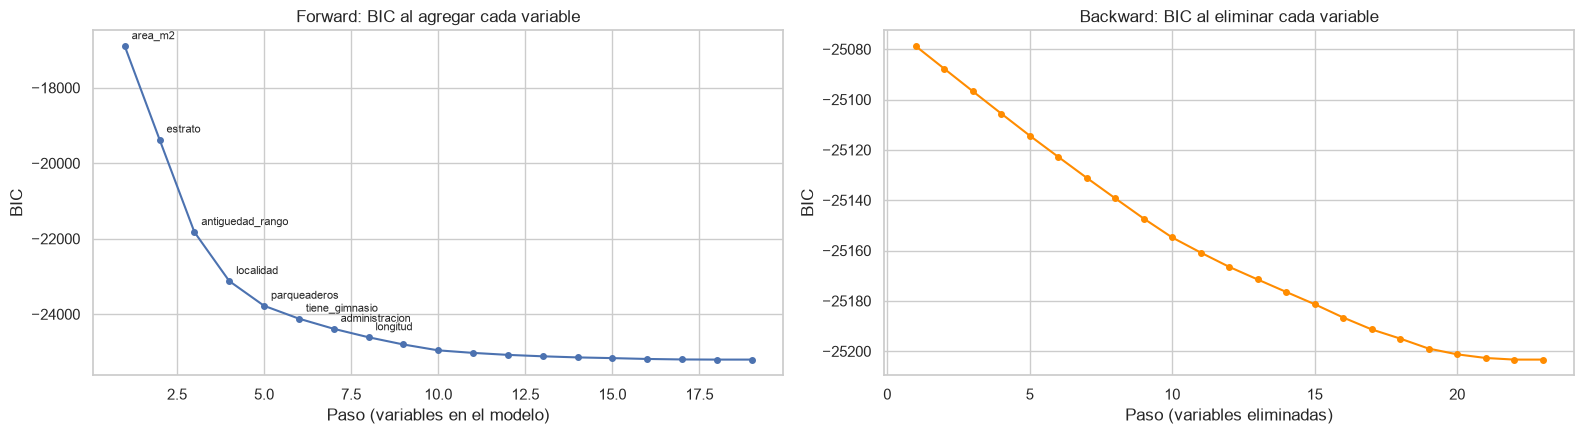

Orden de entrada en Forward (primeras 12):
 paso         variable         BIC
    1          area_m2 -16,897.000
    2          estrato -19,372.000
    3 antiguedad_rango -21,824.000
    4        localidad -23,122.000
    5     parqueaderos -23,777.000
    6   tiene_gimnasio -24,118.000
    7   administracion -24,387.000
    8         longitud -24,612.000
    9          latitud -24,803.000
   10    tiene_piscina -24,958.000
   11     habitaciones -25,026.000
   12            banos -25,078.000

Variables eliminadas por Backward (en orden):
dist_religion_m, religion_500m, hospitales_clinicas_500m, vias_principales_500m, factores_negativos_500m, tiene_ascensor, dist_comercio_m, tiene_jacuzzi, tiene_vigilancia, dist_recreacion_m, comercio_500m, tiene_tina, dist_farmacias_m, dist_transporte_m, transporte_500m, educacion_500m, recreacion_500m, tiene_chimenea, tiene_deposito, dist_factores_negativos_m, dist_parque_m, conjunto_cerrado, tipo_via_principal_cercana


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].plot(hist_forward["paso"], hist_forward["BIC"], marker="o", ms=4)
for _, f in hist_forward.head(8).iterrows():
    ax[0].annotate(f["variable"], (f["paso"], f["BIC"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax[0].set(title="Forward: BIC al agregar cada variable", xlabel="Paso (variables en el modelo)", ylabel="BIC")
ax[1].plot(hist_backward["paso"], hist_backward["BIC"], marker="o", ms=4, color="darkorange")
ax[1].set(title="Backward: BIC al eliminar cada variable", xlabel="Paso (variables eliminadas)", ylabel="BIC")
plt.tight_layout(); plt.show()

print("Orden de entrada en Forward (primeras 12):")
print(hist_forward.head(12).assign(BIC=lambda d: d["BIC"].round(0)).to_string(index=False))
print("\nVariables eliminadas por Backward (en orden):")
print(", ".join(hist_backward["variable_eliminada"]))

In [18]:
# Modelos finales de cada estrategia: Pipeline completo con solo las variables seleccionadas
modelos["Forward (BIC)"] = crear_modelo(LinearRegression(), vars_forward).fit(X_train, y_train)
modelos["Backward (BIC)"] = crear_modelo(LinearRegression(), vars_backward).fit(X_train, y_train)
resultados += evaluar(modelos["Forward (BIC)"], "Forward (BIC)")
resultados += evaluar(modelos["Backward (BIC)"], "Backward (BIC)")

# Comparación de subconjuntos
set_f, set_b = set(vars_forward), set(vars_backward)
print(f"En ambos: {len(set_f & set_b)} | Solo Forward: {sorted(set_f - set_b)} | Solo Backward: {sorted(set_b - set_f)}")
print(f"Índice de Jaccard (coincidencia): {len(set_f & set_b) / len(set_f | set_b):.2f}")
print(f"\nDescartadas por ambas ({len(set(VARIABLES) - set_f - set_b)}): {sorted(set(VARIABLES) - set_f - set_b)}")

En ambos: 18 | Solo Forward: ['dist_factores_negativos_m'] | Solo Backward: ['dist_educacion_m']
Índice de Jaccard (coincidencia): 0.90

Descartadas por ambas (22): ['comercio_500m', 'conjunto_cerrado', 'dist_comercio_m', 'dist_farmacias_m', 'dist_parque_m', 'dist_recreacion_m', 'dist_religion_m', 'dist_transporte_m', 'educacion_500m', 'factores_negativos_500m', 'hospitales_clinicas_500m', 'recreacion_500m', 'religion_500m', 'tiene_ascensor', 'tiene_chimenea', 'tiene_deposito', 'tiene_jacuzzi', 'tiene_tina', 'tiene_vigilancia', 'tipo_via_principal_cercana', 'transporte_500m', 'vias_principales_500m']


**Comparación de los subconjuntos.**

- **Forward y Backward llegan a subconjuntos de 19 variables que coinciden en 18** (índice de Jaccard = 0,90) y con el mismo BIC (−25.203 frente a −25.070 del modelo completo). Solo difieren en una variable de entorno: Forward se queda con `dist_factores_negativos_m` y Backward con `dist_educacion_m`. Son búsquedas voraces que pueden terminar en óptimos locales distintos; que partiendo de extremos opuestos coincidan en 18 de 19 indica que el núcleo del subconjunto es **estable**, y que la variable 19 es intercambiable (aporta casi lo mismo una que otra).
- **Orden de entrada en Forward:** área → estrato → antigüedad → localidad → parqueaderos. Con solo esas cinco variables ya se alcanza el 94 % de la mejora total de BIC; las otras 14 afinan.
- **Se conservan** las 7 variables del inmueble (área, administración, habitaciones, baños, parqueaderos, estrato, antigüedad), **4 de las 11 comodidades** (gimnasio, piscina, parqueadero cubierto y balcón/terraza) y 8 de las 24 de ubicación (localidad, latitud, longitud, distancia a TransMilenio, a hospitales, a vía principal y a factores negativos, y farmacias a 500 m).
- **Ambas descartan 22 variables**: 7 comodidades (ascensor, chimenea, depósito, jacuzzi, tina, vigilancia, conjunto cerrado) y 15 de entorno. No significa que no se relacionen con el precio, sino que **no agregan información una vez se conoce lo demás**: por ejemplo, el ascensor y la vigilancia quedan explicados por estrato y antigüedad, y el jacuzzi (5 % de los anuncios) por piscina y gimnasio.
- **Respuesta a la pregunta del Grupo B:** la distancia Haversine **a TransMilenio sí aporta** (sobrevive a las dos selecciones), aunque su efecto es pequeño frente al de las variables del inmueble. La distancia **a parque no**: ambas la descartan, porque con más de 5.000 parques casi todos los apartamentos tienen uno a pocos metros y la variable casi no discrimina.
- **Antigüedad como bloque:** entró en el paso 3 de Forward con sus 5 dummies y nunca fue candidata a salir en Backward; tratarla como bloque no costó nada y mantiene interpretable la categoría de referencia ("Entre 0 y 5 años").

## 8. Regularización: Ridge (L2)

Ridge minimiza $\text{RSS} + \alpha \sum_j \beta_j^2$: encoge todos los coeficientes hacia cero **sin anularlos**, repartiendo el efecto entre variables correlacionadas. Es la respuesta natural a la multicolinealidad vista en la sección 6.2.

- Variables **estandarizadas** dentro del `Pipeline` (el escalador se reajusta en cada pliegue → sin fuga).
- α elegido con **validación cruzada de 5 pliegues** sobre el MAE en pesos. Se reportan dos valores: el **α mínimo** (menor MAE de validación) y el **α 1-EE** (regla de un error estándar: el α más grande cuyo MAE queda a menos de un error estándar del mínimo, es decir, el modelo más regularizado que es estadísticamente indistinguible del mejor). Se usa el α 1-EE.

In [19]:
alphas_ridge = np.logspace(-2, 4, 40)
busqueda_ridge = GridSearchCV(
    crear_modelo(Ridge()), {"regressor__modelo__alpha": alphas_ridge},
    scoring="neg_mean_absolute_error", cv=CV, n_jobs=-1,
).fit(X_train, y_train)

cv_ridge = pd.DataFrame({
    "alpha": alphas_ridge,
    "mae": -busqueda_ridge.cv_results_["mean_test_score"] / 1e6,
    "ee": busqueda_ridge.cv_results_["std_test_score"] / 1e6 / np.sqrt(CV.get_n_splits()),
})
i_min = cv_ridge["mae"].idxmin()
alpha_ridge_min = cv_ridge.loc[i_min, "alpha"]
umbral = cv_ridge.loc[i_min, "mae"] + cv_ridge.loc[i_min, "ee"]
alpha_ridge = cv_ridge.loc[cv_ridge["mae"] <= umbral, "alpha"].max()          # regla de un error estándar

modelos["Ridge"] = crear_modelo(Ridge(alpha=alpha_ridge)).fit(X_train, y_train)
resultados += evaluar(modelos["Ridge"], "Ridge")
mae_cv_ridge = cv_ridge.loc[cv_ridge["alpha"] == alpha_ridge, "mae"].iloc[0]
print(f"α mínimo = {alpha_ridge_min:.3g} (MAE CV = ${cv_ridge['mae'].min():,.1f} M) | α 1-EE = {alpha_ridge:.3g} (MAE CV = ${mae_cv_ridge:,.1f} M)")
print(f"Error estándar del MAE CV en el mínimo: ${cv_ridge.loc[i_min, 'ee']:,.1f} M")

α mínimo = 0.01 (MAE CV = $238.9 M) | α 1-EE = 203 (MAE CV = $245.4 M)
Error estándar del MAE CV en el mínimo: $6.7 M


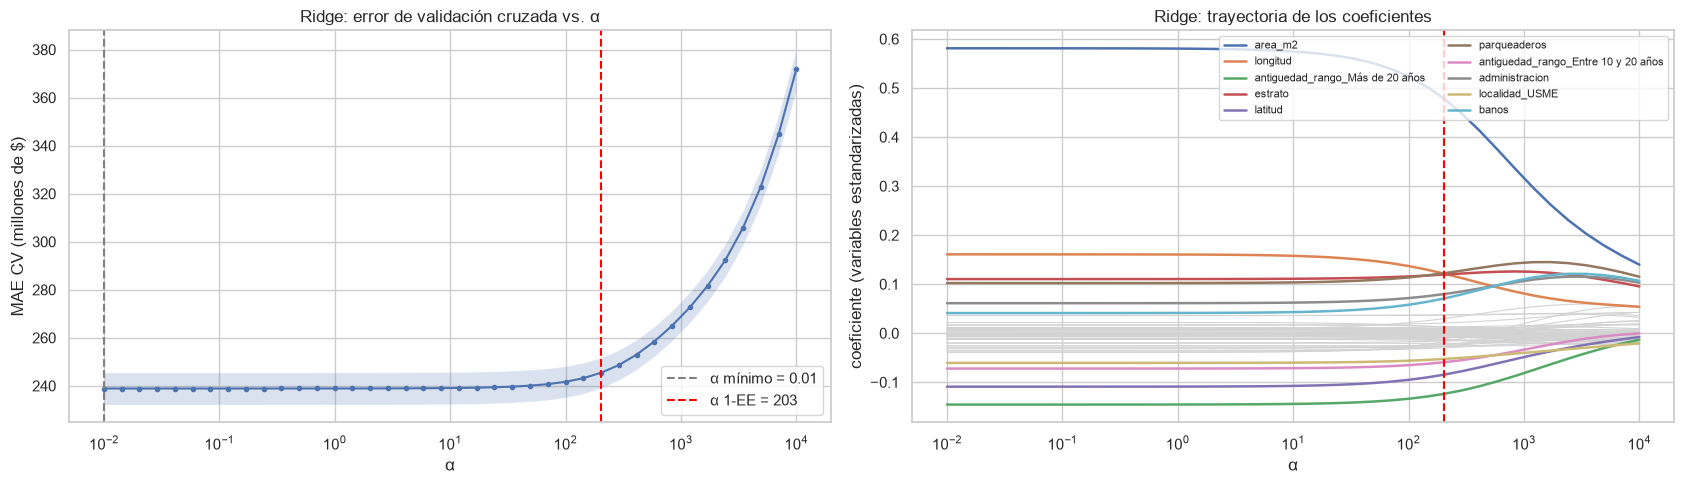

Norma L2 de coeficientes: OLS = 0.6698 | Ridge = 0.5698
Coeficientes exactamente en cero con Ridge: 0


,OLS,Ridge,cambio_%
area_m2,0.581,0.478,-17.690
longitud,0.161,0.121,-24.450
antiguedad_rango_Más de 20 años,-0.146,-0.124,-15.003
estrato,0.110,0.119,8.314
latitud,-0.109,-0.085,-22.486
parqueaderos,0.102,0.122,19.686
antiguedad_rango_Entre 10 y 20 años,-0.072,-0.059,-17.888
administracion,0.061,0.080,30.379
localidad_USME,-0.061,-0.053,-13.171
banos,0.041,0.071,72.512


In [20]:
# Trayectorias de coeficientes: Ridge ajustado sobre la matriz de diseño de train para cada α
coefs_ridge = pd.DataFrame(
    [Ridge(alpha=a).fit(Xt_train, ylog_train).coef_ for a in alphas_ridge], index=alphas_ridge, columns=columnas)
top = coefs_ridge.iloc[0].abs().sort_values(ascending=False).head(10).index

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
ax[0].plot(cv_ridge["alpha"], cv_ridge["mae"], marker="o", ms=3)
ax[0].fill_between(cv_ridge["alpha"], cv_ridge["mae"] - cv_ridge["ee"], cv_ridge["mae"] + cv_ridge["ee"], alpha=0.2)
ax[0].axvline(alpha_ridge_min, color="gray", ls="--", label=f"α mínimo = {alpha_ridge_min:.3g}")
ax[0].axvline(alpha_ridge, color="red", ls="--", label=f"α 1-EE = {alpha_ridge:.3g}")
ax[0].set(xscale="log", title="Ridge: error de validación cruzada vs. α", xlabel="α", ylabel="MAE CV (millones de $)"); ax[0].legend()
ax[1].plot(coefs_ridge.index, coefs_ridge.drop(columns=top), color="lightgray", lw=0.8)
for col in top:
    ax[1].plot(coefs_ridge.index, coefs_ridge[col], lw=1.8, label=col)
ax[1].axvline(alpha_ridge, color="red", ls="--")
ax[1].set(xscale="log", title="Ridge: trayectoria de los coeficientes", xlabel="α", ylabel="coeficiente (variables estandarizadas)")
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

# ¿Cuánto encoge Ridge frente a OLS en el α elegido?
coef_ridge = pd.Series(modelos["Ridge"].regressor_.named_steps["modelo"].coef_, index=columnas)
comparacion = pd.DataFrame({"OLS": ols.params.drop("const"), "Ridge": coef_ridge})
comparacion["cambio_%"] = (comparacion["Ridge"] / comparacion["OLS"] - 1) * 100
print(f"Norma L2 de coeficientes: OLS = {np.linalg.norm(comparacion['OLS']):.4f} | Ridge = {np.linalg.norm(comparacion['Ridge']):.4f}")
print(f"Coeficientes exactamente en cero con Ridge: {(coef_ridge == 0).sum()}")
comparacion.reindex(comparacion["OLS"].abs().sort_values(ascending=False).index).head(10)

**Interpretación de Ridge.**

- **La curva de error es plana** desde α = 0,01 hasta α ≈ 100 y luego sube con fuerza. El mínimo está en el borde inferior de la malla (α = 0,01, que equivale a OLS: \$238,9 M), y la diferencia con el α 1-EE (α = 203, \$245,4 M) es menor que un error estándar (\$6,7 M). Es decir: **la regularización L2 no mejora el error de predicción**, pero tampoco lo empeora de forma apreciable hasta α ≈ 200.
- ¿Por qué no mejora? Porque hay **8.179 observaciones para 62 columnas** (132 por parámetro): la varianza de OLS ya es baja y no hay sobreajuste que corregir. Ridge ayuda cuando *p* es grande frente a *n*, que no es este caso.
- **Lo que sí cambia son los coeficientes.** Con α = 203 la norma L2 baja de 0,670 a 0,570 y **ningún coeficiente llega a cero**. En las trayectorias se ve el patrón típico de Ridge con variables correlacionadas: el coeficiente dominante se encoge (`area_m2` −18 %, `longitud` −24 %, `latitud` −22 %) y el efecto se **redistribuye** hacia sus compañeras correlacionadas, que crecen (`banos` +73 %, `administracion` +30 %, `parqueaderos` +20 %). Es exactamente el grupo de VIF alto de la sección 6.2: Ridge reparte el "efecto tamaño" entre área, baños y parqueaderos en vez de cargarlo en una sola.
- **Conclusión:** Ridge entrega coeficientes más estables frente a la multicolinealidad, pero no reduce variables (sigue usando las 42) ni mejora la predicción.

## 9. Regularización: Lasso (L1)

Lasso minimiza $\frac{1}{2n}\text{RSS} + \alpha \sum_j |\beta_j|$. La penalización L1 lleva coeficientes **exactamente a cero**, es decir, hace selección automática de variables. Con ~20 comodidades binarias correlacionadas entre sí (quien tiene gimnasio suele tener salón comunal y BBQ) es el escenario donde más valor aporta.

Se reportan dos valores de α, ambos obtenidos por validación cruzada de 5 pliegues:

- **α mínimo:** el de menor MAE de validación.
- **α 1-EE (regla de un error estándar):** el α **más grande** cuyo MAE está a menos de un error estándar del mínimo. Es el modelo más simple que es estadísticamente indistinguible del mejor; se prefiere porque pedirá menos datos al usuario en producción.

In [21]:
alphas_lasso = np.logspace(-4, -0.7, 40)
busqueda_lasso = GridSearchCV(
    crear_modelo(Lasso(max_iter=50_000)), {"regressor__modelo__alpha": alphas_lasso},
    scoring="neg_mean_absolute_error", cv=CV, n_jobs=-1,
).fit(X_train, y_train)

cv_lasso = pd.DataFrame({
    "alpha": alphas_lasso,
    "mae": -busqueda_lasso.cv_results_["mean_test_score"] / 1e6,
    "ee": busqueda_lasso.cv_results_["std_test_score"] / 1e6 / np.sqrt(CV.get_n_splits()),
})
i_min = cv_lasso["mae"].idxmin()
alpha_lasso_min = cv_lasso.loc[i_min, "alpha"]
umbral = cv_lasso.loc[i_min, "mae"] + cv_lasso.loc[i_min, "ee"]
alpha_lasso_1ee = cv_lasso.loc[cv_lasso["mae"] <= umbral, "alpha"].max()      # regla de un error estándar

modelos["Lasso"] = crear_modelo(Lasso(alpha=alpha_lasso_1ee, max_iter=50_000)).fit(X_train, y_train)
resultados += evaluar(modelos["Lasso"], "Lasso")
mae_cv_lasso = cv_lasso.loc[cv_lasso["alpha"] == alpha_lasso_1ee, "mae"].iloc[0]
print(f"α mínimo = {alpha_lasso_min:.4g} (MAE CV = ${cv_lasso['mae'].min():,.1f} M) | α 1-EE = {alpha_lasso_1ee:.4g} (MAE CV = ${mae_cv_lasso:,.1f} M)")

α mínimo = 0.0001 (MAE CV = $238.9 M) | α 1-EE = 0.004924 (MAE CV = $244.5 M)


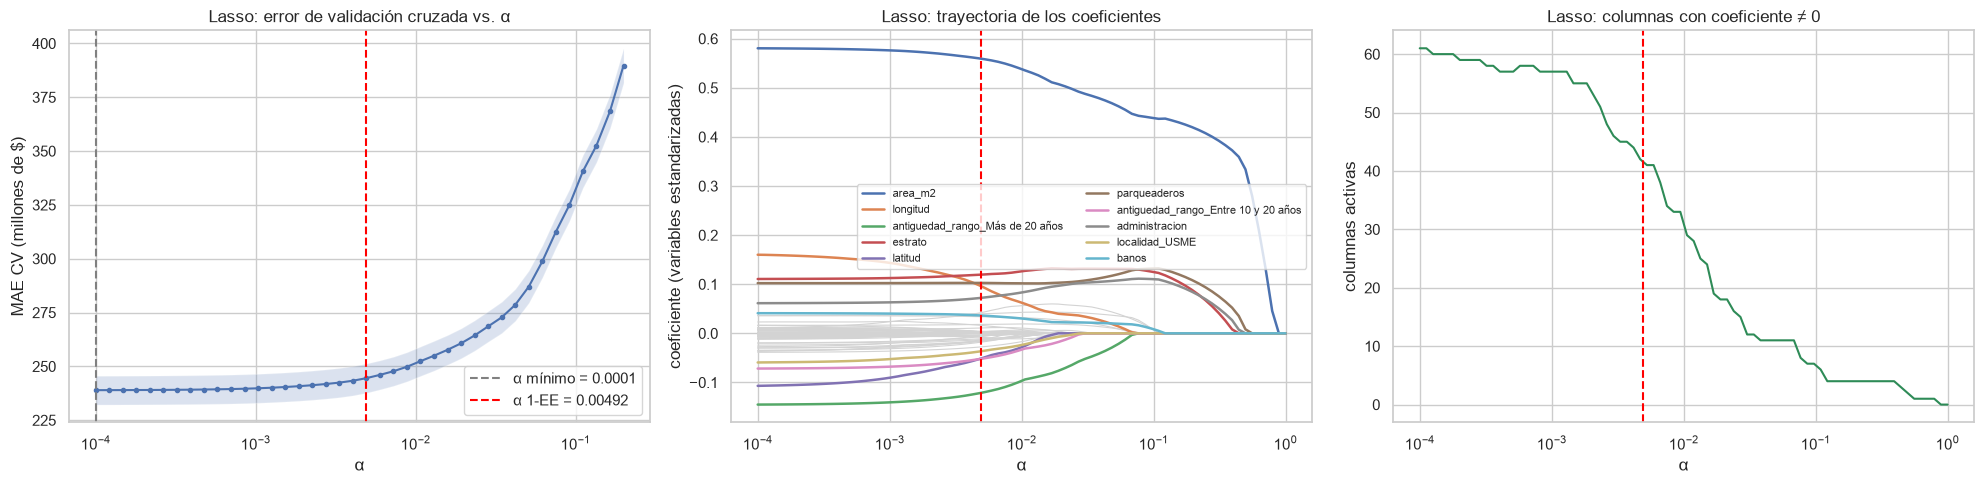

In [22]:
# Trayectoria de coeficientes Lasso sobre la matriz de diseño de train
alphas_tray, coefs_tray, _ = lasso_path(Xt_train.values, (ylog_train - ylog_train.mean()).values, alphas=np.logspace(-4, 0, 80))
coefs_lasso = pd.DataFrame(coefs_tray.T, index=alphas_tray, columns=columnas).sort_index()
n_activas = (coefs_lasso != 0).sum(axis=1)
top = coefs_lasso.iloc[0].abs().sort_values(ascending=False).head(10).index

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].plot(cv_lasso["alpha"], cv_lasso["mae"], marker="o", ms=3)
ax[0].fill_between(cv_lasso["alpha"], cv_lasso["mae"] - cv_lasso["ee"], cv_lasso["mae"] + cv_lasso["ee"], alpha=0.2)
ax[0].axvline(alpha_lasso_min, color="gray", ls="--", label=f"α mínimo = {alpha_lasso_min:.3g}")
ax[0].axvline(alpha_lasso_1ee, color="red", ls="--", label=f"α 1-EE = {alpha_lasso_1ee:.3g}")
ax[0].set(xscale="log", title="Lasso: error de validación cruzada vs. α", xlabel="α", ylabel="MAE CV (millones de $)"); ax[0].legend()
ax[1].plot(coefs_lasso.index, coefs_lasso.drop(columns=top), color="lightgray", lw=0.8)
for col in top:
    ax[1].plot(coefs_lasso.index, coefs_lasso[col], lw=1.8, label=col)
ax[1].axvline(alpha_lasso_1ee, color="red", ls="--")
ax[1].set(xscale="log", title="Lasso: trayectoria de los coeficientes", xlabel="α", ylabel="coeficiente (variables estandarizadas)")
ax[1].legend(fontsize=8, ncol=2)
ax[2].plot(n_activas.index, n_activas.values, color="seagreen")
ax[2].axvline(alpha_lasso_1ee, color="red", ls="--")
ax[2].set(xscale="log", title="Lasso: columnas con coeficiente ≠ 0", xlabel="α", ylabel="columnas activas")
plt.tight_layout(); plt.show()

In [23]:
# ¿Qué sobrevive en Lasso? Una variable (bloque) sobrevive si al menos una de sus columnas tiene coeficiente ≠ 0
coef_lasso = pd.Series(modelos["Lasso"].regressor_.named_steps["modelo"].coef_, index=columnas)
vars_lasso = [v for v in VARIABLES if (coef_lasso[BLOQUES[v]] != 0).any()]
print(f"Columnas con coeficiente ≠ 0: {(coef_lasso != 0).sum()} de {len(columnas)}")
print(f"Variables que sobreviven: {len(vars_lasso)} de {len(VARIABLES)}")
print(f"Variables eliminadas por Lasso: {sorted(set(VARIABLES) - set(vars_lasso))}")

# Coincidencia entre Forward, Backward y Lasso
tabla_sel = pd.DataFrame({
    "Forward": [v in vars_forward for v in VARIABLES],
    "Backward": [v in vars_backward for v in VARIABLES],
    "Lasso": [v in vars_lasso for v in VARIABLES],
}, index=VARIABLES)
tabla_sel["Grupo"] = ["Comodidad" if v in VARS_BIN else "Ubicación" if (v in VARIABLES_DISTANCIA + VARIABLES_CONTEO or v in ("latitud", "longitud", "localidad", "tipo_via_principal_cercana")) else "Inmueble" for v in VARIABLES]
tabla_sel["Métodos que la eligen"] = tabla_sel[["Forward", "Backward", "Lasso"]].sum(axis=1)

resumen_sel = tabla_sel.groupby("Grupo")[["Forward", "Backward", "Lasso"]].sum().assign(Candidatas=tabla_sel.groupby("Grupo").size())
display(resumen_sel)
print("Elegidas por los 3 métodos:", int((tabla_sel["Métodos que la eligen"] == 3).sum()),
      "| por ninguno:", int((tabla_sel["Métodos que la eligen"] == 0).sum()))
print("Comodidades que sobreviven en Lasso:", [v for v in VARS_BIN if v in vars_lasso])
print("Comodidades eliminadas por Lasso   :", [v for v in VARS_BIN if v not in vars_lasso])
display(tabla_sel.replace({True: "✔", False: "—"}).sort_values(["Métodos que la eligen", "Grupo"], ascending=[False, True]))

Columnas con coeficiente ≠ 0: 42 de 62
Variables que sobreviven: 26 de 42
Variables eliminadas por Lasso: ['conjunto_cerrado', 'dist_comercio_m', 'dist_farmacias_m', 'dist_parque_m', 'dist_recreacion_m', 'dist_religion_m', 'educacion_500m', 'factores_negativos_500m', 'hospitales_clinicas_500m', 'recreacion_500m', 'religion_500m', 'tiene_ascensor', 'tiene_chimenea', 'tiene_deposito', 'tiene_jacuzzi', 'tiene_vigilancia']


,Forward,Backward,Lasso,Candidatas
Grupo,,,,
Comodidad,4,4,5,11
Inmueble,7,7,7,7
Ubicación,8,8,14,24


Elegidas por los 3 métodos: 18 | por ninguno: 16
Comodidades que sobreviven en Lasso: ['tiene_tina', 'parqueadero_cubierto', 'tiene_gimnasio', 'tiene_piscina', 'tiene_balcon_terraza']
Comodidades eliminadas por Lasso   : ['tiene_jacuzzi', 'tiene_ascensor', 'conjunto_cerrado', 'tiene_vigilancia', 'tiene_chimenea', 'tiene_deposito']


,Forward,Backward,Lasso,Grupo,Métodos que la eligen
parqueadero_cubierto,✔,✔,✔,Comodidad,3
tiene_gimnasio,✔,✔,✔,Comodidad,3
tiene_piscina,✔,✔,✔,Comodidad,3
tiene_balcon_terraza,✔,✔,✔,Comodidad,3
area_m2,✔,✔,✔,Inmueble,3
administracion,✔,✔,✔,Inmueble,3
habitaciones,✔,✔,✔,Inmueble,3
banos,✔,✔,✔,Inmueble,3
parqueaderos,✔,✔,✔,Inmueble,3
estrato,✔,✔,✔,Inmueble,3


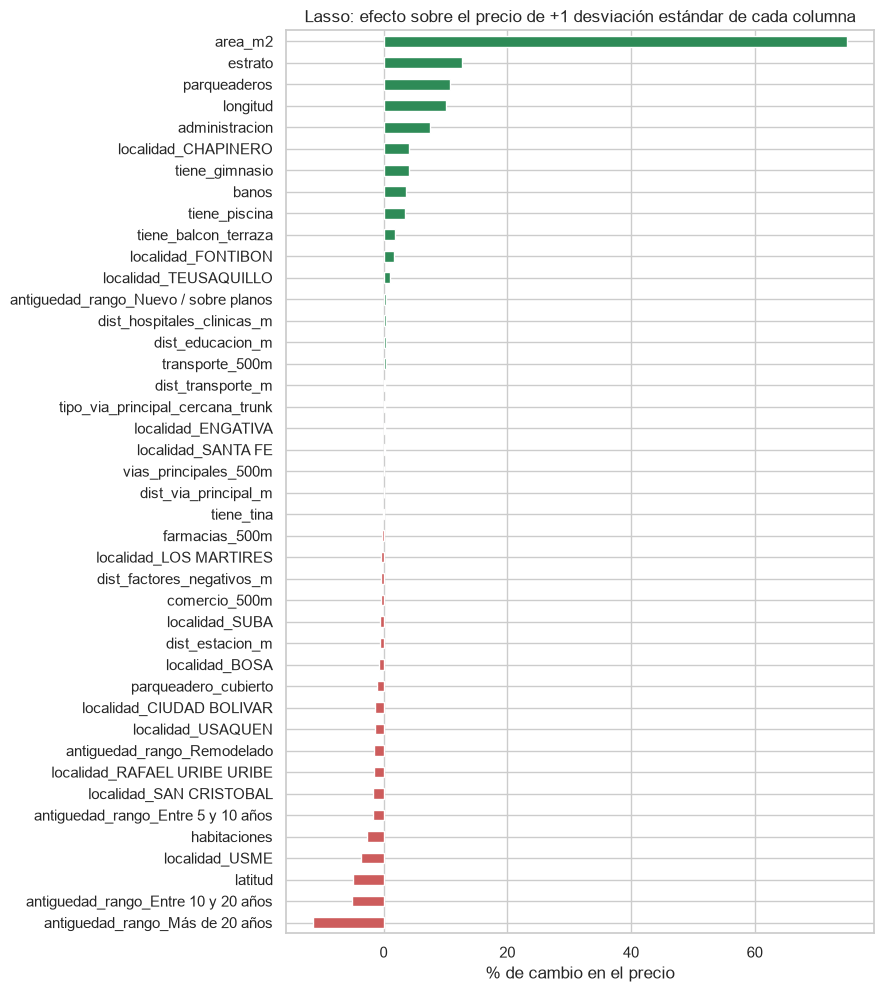

In [24]:
# Coeficientes Lasso más importantes, expresados como efecto porcentual sobre el precio por +1 desviación estándar
efecto = ((np.exp(coef_lasso[coef_lasso != 0]) - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, max(5, 0.24 * len(efecto))))
efecto.plot.barh(ax=ax, color=np.where(efecto > 0, "seagreen", "indianred"))
ax.set(title="Lasso: efecto sobre el precio de +1 desviación estándar de cada columna", xlabel="% de cambio en el precio")
plt.tight_layout(); plt.show()

**Interpretación de Lasso.**

- **Curva de error:** igual que en Ridge, el MAE es plano para α pequeños (mínimo \$238,9 M en α = 0,0001) y se dispara a partir de α ≈ 0,01. Con la regla de un error estándar se elige **α = 0,0049** (MAE CV \$244,5 M).
- **¿Qué sobrevive?** De 62 columnas quedan **42 con coeficiente distinto de cero**, que corresponden a **26 de las 42 variables**. Lasso elimina 16 variables completas: 6 comodidades (jacuzzi, ascensor, conjunto cerrado, vigilancia, chimenea, depósito) y 10 de entorno (distancia a parque, a farmacias, a comercio, a recreación y a iglesias; conteos de hospitales, educación, recreación, iglesias y factores negativos a 500 m).
- **Trayectorias:** las primeras en morir al aumentar α son las comodidades y los conteos de entorno; las últimas en resistir son `area_m2`, `parqueaderos`, `estrato` y `administracion` (con α ≈ 0,1 solo quedan esas 4 columnas activas), precedidas por la antigüedad y la longitud: prácticamente las mismas que Forward eligió primero. El gráfico de columnas activas muestra que con α ≈ 0,02 quedarían menos de 20 columnas, pero el MAE de validación subiría de \$239 M a cerca de \$260 M.
- **Comodidades (el punto fuerte del Grupo B):** de 11 sobreviven **5 en Lasso frente a 4 en Forward/Backward**. Las 4 de Forward/Backward (gimnasio, piscina, parqueadero cubierto, balcón/terraza) están todas dentro de las 5 de Lasso, que conserva además la tina. Las 6 que elimina Lasso también las eliminan Forward y Backward: **hay consenso total en que jacuzzi, ascensor, conjunto cerrado, vigilancia, chimenea y depósito no aportan**. Las comodidades que más pesan son gimnasio (+3,8 %) y piscina (+3,7 %), seguidas de balcón/terraza (+1,7 %): las *zonas comunes de conjunto premium* pesan más que las del interior del apartamento.
- **¿Coincide con Forward/Backward?** En lo esencial sí: **18 variables son elegidas por los tres métodos** y 16 no son elegidas por ninguno. Lasso contiene las 19 de Forward y las 19 de Backward, y retiene además 6 variables débiles que BIC considera prescindibles (tina, distancia y conteo de paraderos, comercio a 500 m, vías a 500 m y tipo de vía). La diferencia es de *criterio*: BIC cobra un costo fijo por parámetro (decisión todo o nada), mientras que Lasso permite que una variable se quede con un coeficiente casi nulo.
- **Signos que no deben leerse como causales:** `parqueadero_cubierto` sale negativo (−1,8 % en el modelo final). No es que reste valor: una vez controlados área, estrato y número de parqueaderos, captura diferencias de tipo de edificio y de fuente del anuncio (34 % en Metrocuadrado frente a 8 % en Habi).

## 10. Comparación de modelos

Tabla con las métricas elegidas para los cinco modelos, en entrenamiento y en prueba (el conjunto de prueba se usa aquí por única vez). Se agrega el MAE de validación cruzada sobre *train*, que es la cifra con la que se toman las decisiones.

In [25]:
tabla = pd.DataFrame(resultados).pivot(index="Modelo", columns="Conjunto").reindex(list(modelos))
tabla = tabla.reindex(columns=["Train", "Test"], level=1)

# MAE de validación cruzada (5 pliegues, solo train) para todos los modelos
mae_cv = {
    nombre: -cross_val_score(m, X_train, y_train, scoring="neg_mean_absolute_error", cv=CV, n_jobs=-1).mean() / 1e6
    for nombre, m in modelos.items()
}
n_vars = {"Base (OLS)": len(VARIABLES), "Forward (BIC)": len(vars_forward), "Backward (BIC)": len(vars_backward),
          "Ridge": len(VARIABLES), "Lasso": len(vars_lasso)}

comparativa = pd.DataFrame({
    "Variables": pd.Series(n_vars),
    "MAE CV (M$)": pd.Series(mae_cv),
    "MAE train (M$)": tabla[("MAE (M$)", "Train")], "MAE test (M$)": tabla[("MAE (M$)", "Test")],
    "RMSE train (M$)": tabla[("RMSE (M$)", "Train")], "RMSE test (M$)": tabla[("RMSE (M$)", "Test")],
    "R² train": tabla[("R²", "Train")], "R² test": tabla[("R²", "Test")],
    "MAPE train (%)": tabla[("MAPE (%)", "Train")], "MAPE test (%)": tabla[("MAPE (%)", "Test")],
}).reindex(list(modelos))
comparativa["Brecha MAE test-train (%)"] = (comparativa["MAE test (M$)"] / comparativa["MAE train (M$)"] - 1) * 100
comparativa.to_csv(DIR_OUTPUT / "tabla_comparativa.csv", encoding="utf-8-sig")
comparativa.style.format({c: "{:,.1f}" for c in comparativa.columns if "M$" in c or "%" in c} | {"R² train": "{:.4f}", "R² test": "{:.4f}"}) \
    .highlight_min(subset=["MAE CV (M$)", "MAE test (M$)", "RMSE test (M$)"], color="#c8e6c9")

,Variables,MAE CV (M$),MAE train (M$),MAE test (M$),RMSE train (M$),RMSE test (M$),R² train,R² test,MAPE train (%),MAPE test (%),Brecha MAE test-train (%)
Base (OLS),42,238.9,237.2,241.0,511.9,512.1,0.8458,0.8590,16.1,15.9,1.6
Forward (BIC),19,238.9,237.8,240.1,509.8,508.2,0.8471,0.8612,16.3,16.0,1.0
Backward (BIC),19,239.3,238.2,240.0,510.6,508.5,0.8466,0.8610,16.3,15.9,0.7
Ridge,42,245.4,242.3,247.4,529.4,536.4,0.8351,0.8454,16.3,16.0,2.1
Lasso,26,244.5,243.4,247.2,527.9,534.5,0.8361,0.8464,16.4,16.1,1.6


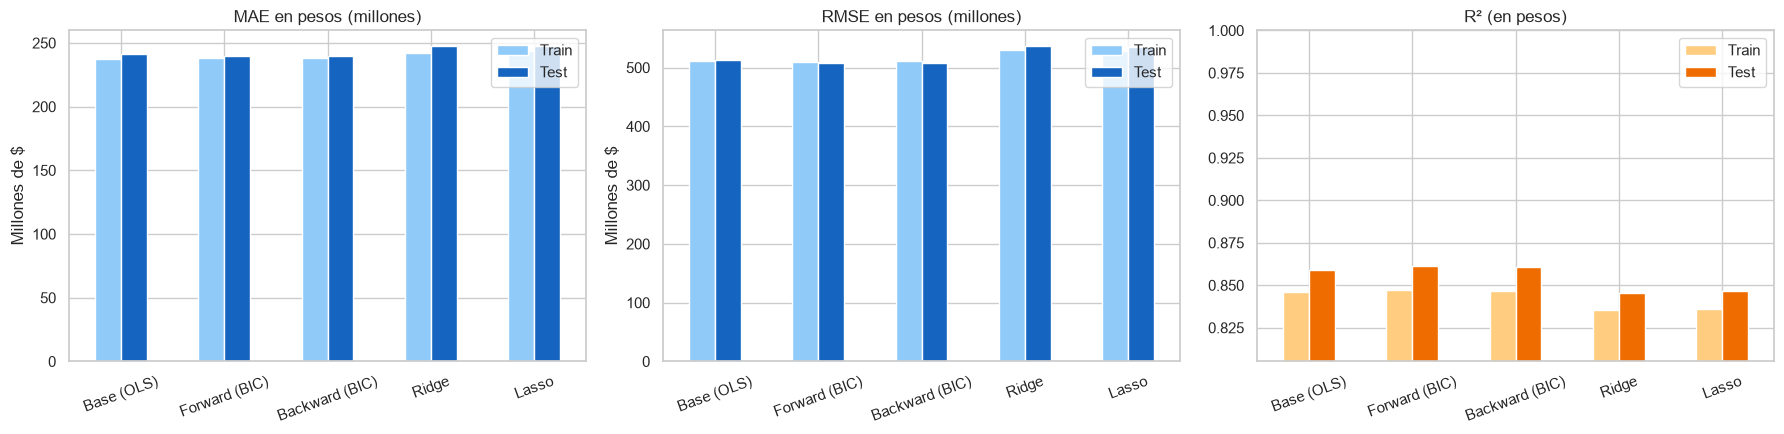

Diferencia entre el mejor y el peor modelo en MAE de prueba: $7.4 M (0.89 % del precio mediano de $828 M)


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, met in zip(ax, ["MAE", "RMSE"]):
    comparativa[[f"{met} train (M$)", f"{met} test (M$)"]].plot.bar(ax=a, rot=20, color=["#90caf9", "#1565c0"])
    a.set(title=f"{met} en pesos (millones)", ylabel="Millones de $"); a.legend(["Train", "Test"])
comparativa[["R² train", "R² test"]].plot.bar(ax=ax[2], rot=20, color=["#ffcc80", "#ef6c00"])
ax[2].set(title="R² (en pesos)", ylim=(comparativa[["R² train", "R² test"]].min().min() - 0.03, 1)); ax[2].legend(["Train", "Test"])
plt.tight_layout(); plt.show()

rango = comparativa["MAE test (M$)"].max() - comparativa["MAE test (M$)"].min()
print(f"Diferencia entre el mejor y el peor modelo en MAE de prueba: ${rango:,.1f} M "
      f"({rango / (y_test.median() / 1e6) * 100:.2f} % del precio mediano de ${y_test.median()/1e6:,.0f} M)")

**Análisis de la tabla comparativa.**

| Pregunta | Respuesta |
|---|---|
| **¿Cuál modelo tiene mejor desempeño?** | En validación cruzada hay un triple empate entre el modelo **base** (\$238,9 M), **Forward** (\$238,9 M) y **Backward** (\$239,3 M); Lasso (\$244,5 M) y Ridge (\$245,4 M) quedan algo atrás. En prueba el orden es Backward \$240,0 M → Forward \$240,1 M → Base \$241,0 M → Lasso \$247,2 M → Ridge \$247,4 M. |
| **¿La diferencia es relevante en pesos?** | **No.** Entre el mejor y el peor hay **\$7,4 M de MAE**, el 0,89 % del precio mediano (\$828 M), y es del orden del error estándar de la validación cruzada (\$6,7 M). Los cinco modelos son prácticamente equivalentes para predecir. |
| **¿Hay sobreajuste?** | **No.** El MAE de prueba es apenas entre 0,7 % y 2,1 % mayor que el de entrenamiento en los cinco modelos, y el MAPE es casi igual (16,3 % frente a 16,0 %). Como la partición del EDA dejó *train* y *test* con el mismo precio mediano (\$830 M y \$828 M), las cifras son directamente comparables, y el MAE de validación cruzada (\$239 M) confirma las dos. |
| **¿Sirvió la regularización?** | Para **predecir**, no: con 132 observaciones por parámetro OLS ya tiene poca varianza, y Ridge y Lasso con α 1-EE pagan ~\$6–7 M de MAE a cambio de coeficientes más pequeños. Para **entender**, sí: Ridge mostró cómo se reparte el efecto entre variables colineales y Lasso confirmó, por una vía independiente, qué variables sobran. |
| **RMSE frente a MAE** | El RMSE (\$508 M) duplica al MAE (\$240 M) en todos los modelos: hay **pocos errores muy grandes** concentrados en apartamentos costosos. Ningún modelo lineal lo corrige; es una limitación de la familia de modelos, no de la selección de variables. |

## 11. Modelo final y exportación de artefactos para producción

### Elección del modelo final: regresión lineal con las 19 variables de Forward

Como los cinco modelos predicen igual de bien, la decisión se toma con criterios de **negocio y de operación**:

1. **Error equivalente al mejor:** MAE de validación cruzada de \$238,9 M (empatado con el modelo base) y MAE de prueba de \$240,1 M, incluso \$1,0 M menor que el del modelo base.
2. **Parsimonia:** usa **19 variables en lugar de 42**. En producción eso significa un formulario con 12 campos (8 datos del inmueble y 4 comodidades) y solo 7 variables calculadas a partir de la dirección. Lasso necesitaría 26 y Ridge las 42, sin ganar precisión.
3. **Robustez de la selección:** Forward y Backward coinciden en 18 de las 19 variables, y las 19 sobreviven también en Lasso.
4. **Forward frente a Backward:** tienen el mismo BIC y solo difieren en una variable de entorno. Se elige Forward por tener el menor MAE de validación cruzada (\$238,9 M frente a \$239,3 M); en prueba la diferencia es de \$0,05 M, es decir, ninguna.
5. **Interpretabilidad:** es un OLS sin penalización; cada coeficiente se lee como un efecto porcentual sobre el precio y se puede explicar a un asesor o a un cliente.
6. **Menos riesgo operativo:** menos variables de entrada es menos información que pedir, menos errores de digitación y menos dependencia de capas geográficas externas.

El modelo se exporta **entrenado con *train*** (no se reentrena con toda la base) para que las métricas de prueba reportadas correspondan exactamente al artefacto entregado.

In [27]:
MODELO_FINAL = "Forward (BIC)"
modelo_final = modelos[MODELO_FINAL]

# Columnas y coeficientes del modelo final (los nombres salen de su propio preprocesador)
pipeline_final = modelo_final.regressor_
cols_final = list(pipeline_final.named_steps["prep"].get_feature_names_out())
coef_final = pd.Series(pipeline_final.named_steps["modelo"].coef_, index=cols_final)

# Variables originales que el modelo final realmente usa (coeficiente ≠ 0) -> son las que pedirá el formulario de la app
vars_modelo = [v for v in VARIABLES
               if any(coef_final.get(col, 0) != 0 for col in BLOQUES[v])]
VARS_GEO = VARIABLES_DISTANCIA + VARIABLES_CONTEO + ["tipo_via_principal_cercana"]
vars_usuario = [v for v in vars_modelo if v not in VARS_GEO and v not in ("latitud", "longitud")]
vars_automaticas = [v for v in vars_modelo if v in VARS_GEO or v in ("latitud", "longitud")]
print(f"Modelo final: {MODELO_FINAL} | variables usadas: {len(vars_modelo)} ({len(cols_final)} columnas)")
print(f"  Las digita el usuario ({len(vars_usuario)}): {vars_usuario}")
print(f"  Se calculan con la dirección ({len(vars_automaticas)}): {vars_automaticas}")

Modelo final: Forward (BIC) | variables usadas: 19 (38 columnas)
  Las digita el usuario (12): ['area_m2', 'administracion', 'habitaciones', 'banos', 'parqueaderos', 'estrato', 'parqueadero_cubierto', 'tiene_gimnasio', 'tiene_piscina', 'tiene_balcon_terraza', 'antiguedad_rango', 'localidad']
  Se calculan con la dirección (7): ['dist_estacion_m', 'dist_hospitales_clinicas_m', 'dist_factores_negativos_m', 'dist_via_principal_m', 'latitud', 'longitud', 'farmacias_500m']


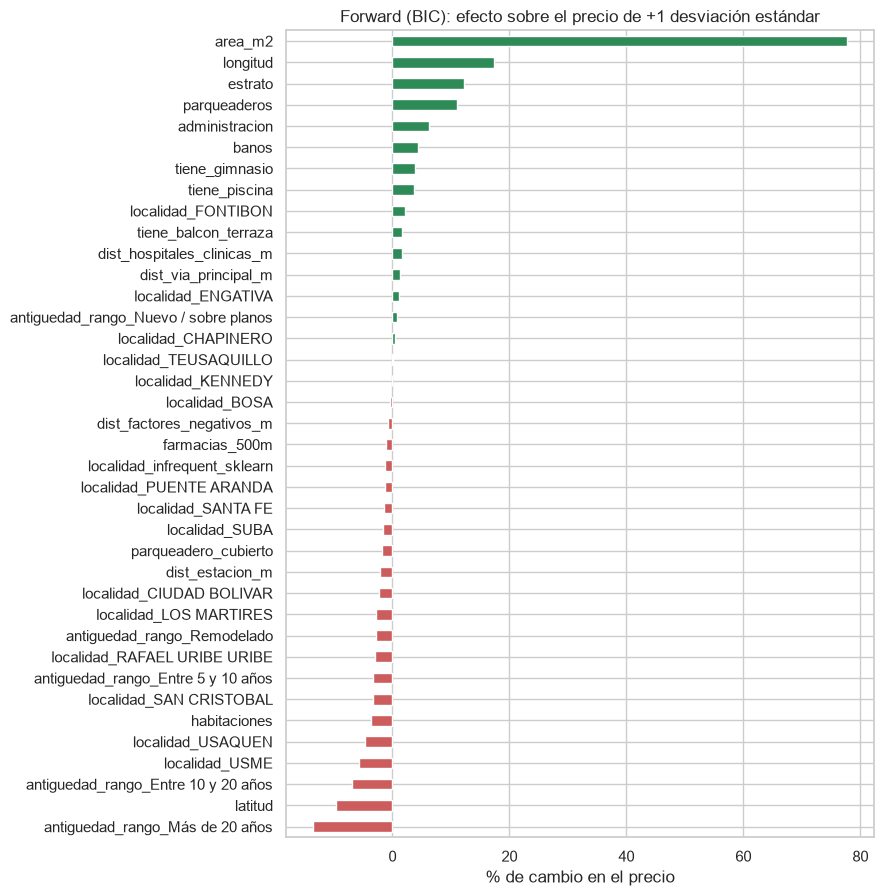

In [28]:
# Coeficientes del modelo final como efecto porcentual sobre el precio por +1 desviación estándar de cada columna
efecto_final = ((np.exp(coef_final) - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, max(5, 0.24 * len(efecto_final))))
efecto_final.plot.barh(ax=ax, color=np.where(efecto_final > 0, "seagreen", "indianred"))
ax.set(title=f"{MODELO_FINAL}: efecto sobre el precio de +1 desviación estándar", xlabel="% de cambio en el precio")
plt.tight_layout(); plt.show()

,Precio mediano (M$),MAE (M$),MAPE (%),Sesgo medio (%)
precio_venta,,,,
Q1 (más económicos),245.000,37.000,15.200,4.500
Q2,490.000,62.400,12.500,2.000
Q3,835.000,136.600,16.200,4.700
Q4,"1,430.000",258.400,17.500,3.100
Q5 (más costosos),"2,900.000",714.100,18.600,-8.200


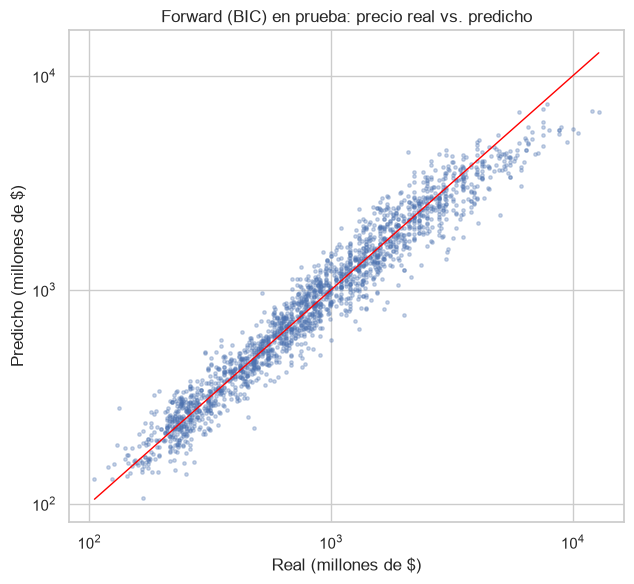

In [29]:
# Error del modelo final por segmento de precio (en prueba): ¿dónde se equivoca más?
pred_test = pd.Series(modelo_final.predict(X_test), index=y_test.index)
segmentos = pd.qcut(y_test, 5, labels=["Q1 (más económicos)", "Q2", "Q3", "Q4", "Q5 (más costosos)"])
por_segmento = pd.DataFrame({
    "Precio mediano (M$)": y_test.groupby(segmentos, observed=True).median() / 1e6,
    "MAE (M$)": (pred_test - y_test).abs().groupby(segmentos, observed=True).mean() / 1e6,
    "MAPE (%)": ((pred_test - y_test).abs() / y_test).groupby(segmentos, observed=True).mean() * 100,
    "Sesgo medio (%)": ((pred_test - y_test) / y_test).groupby(segmentos, observed=True).mean() * 100,
})
display(por_segmento.round(1))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test / 1e6, pred_test / 1e6, s=6, alpha=0.3)
lim = [y_test.min() / 1e6, y_test.max() / 1e6]
ax.plot(lim, lim, color="red", lw=1)
ax.set(xscale="log", yscale="log", title=f"{MODELO_FINAL} en prueba: precio real vs. predicho", xlabel="Real (millones de $)", ylabel="Predicho (millones de $)")
plt.tight_layout(); plt.show()

**Dónde se equivoca el modelo final.** El error porcentual va de 12 % a 19 % según el segmento, pero en pesos el quintil más costoso concentra el problema: MAE de **\$714 M** frente a \$37 M en el más económico. Además hay un **sesgo sistemático**: el modelo sobrestima entre 2 % y 5 % los cuatro primeros quintiles y **subestima ~8 % el quintil de lujo**. Es la huella de una relación que no es perfectamente lineal en los extremos (lo que insinuaba el gráfico de residuales) y explica por qué el RMSE duplica al MAE.

### 11.1 Exportación de artefactos

Se exporta el `Pipeline` completo (imputación + transformaciones + escalado + one-hot + regresión + exponencial), las capas geográficas compactas, los metadatos que alimentan el formulario de la app y un ejemplo de datos de entrada.

In [30]:
# Banda de incertidumbre: cuantiles del error relativo con predicciones fuera de muestra (CV en train)
pred_cv = cross_val_predict(modelo_final, X_train, y_train, cv=CV, n_jobs=-1)
ratio = y_train / pred_cv                       # precio real / precio predicho
q10, q90 = np.quantile(ratio, [0.10, 0.90])
print(f"El 80 % de los precios reales cae entre {q10:.2f} y {q90:.2f} veces el precio predicho")

El 80 % de los precios reales cae entre 0.77 y 1.29 veces el precio predicho


In [31]:
# ---------- 1) Modelo serializado: Pipeline completo (imputación + escalado + one-hot + regresión + exp) ------
joblib.dump(modelo_final, DIR_OUTPUT / "modelo_final.joblib", compress=3)

# ---------- 2) Capas geográficas compactas (para calcular las variables de ubicación de una dirección nueva) --
geo.guardar(DIR_OUTPUT / "capas_geo.joblib")

# ---------- 3) Coeficientes y selección de variables (documentación) ------------------------------------------
pd.DataFrame({"coeficiente": coef_final, "efecto_%_por_1_desv": (np.exp(coef_final) - 1) * 100}) \
    .rename_axis("columna").to_csv(DIR_OUTPUT / "coeficientes_modelo_final.csv", encoding="utf-8-sig")
tabla_sel.replace({True: "si", False: "no"}).to_csv(DIR_OUTPUT / "variables_seleccionadas.csv", encoding="utf-8-sig")

# ---------- 4) Ejemplo de datos de entrada (un apartamento nuevo, tal como lo digita un usuario) --------------
ejemplo = {
    "direccion": "Calle 94 # 18 - 65, Bogotá",
    "latitud": 4.68055, "longitud": -74.05351,
    "area_m2": 88, "habitaciones": 2, "banos": 2, "parqueaderos": 1, "estrato": 6,
    "antiguedad_rango": "Más de 20 años", "administracion": 980000, "localidad": "auto",
    **{v: int(v in ("tiene_ascensor", "tiene_vigilancia")) for v in VARS_BIN},
}
with open(DIR_OUTPUT / "ejemplo_entrada.json", "w", encoding="utf-8") as f:
    json.dump(ejemplo, f, ensure_ascii=False, indent=2)

# ---------- 5) Metadatos: qué pide el formulario, rangos válidos, métricas y versiones ------------------------
def campo(v):
    # Describe un campo del formulario a partir de los datos de train
    c = {"nombre": v, "etiqueta": ETIQUETAS.get(v, v)}
    if v in VARS_BIN:
        c["tipo"] = "binaria"
    elif v in VARS_CAT:
        opciones = prep.RANGOS_ANTIGUEDAD if v == "antiguedad_rango" else sorted(X_train[v].dropna().unique())
        c.update(tipo="categoria", opciones=list(opciones))
    else:
        s = X_train[v].dropna()
        c.update(tipo="numero", minimo=float(s.min()), maximo=float(s.max()), mediana=float(s.median()),
                 entero=bool(v not in ("area_m2", "administracion")), opcional=bool(v == "administracion"))
    return c

fila_test = comparativa.loc[MODELO_FINAL]
metadata = {
    "modelo": MODELO_FINAL,
    "descripcion": "Regresión lineal múltiple sobre log(precio_venta) con las variables elegidas por selección "
                   "hacia adelante/atrás (criterio BIC, variables categóricas en bloque). El Pipeline devuelve pesos.",
    "fecha_entrenamiento": date.today().isoformat(),
    "semilla": SEMILLA,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "variables_candidatas": VARIABLES,
    "variables_modelo": vars_modelo,
    "campos_formulario": [campo(v) for v in vars_usuario],
    "variables_calculadas_con_la_direccion": vars_automaticas,
    "metricas_test": {"MAE": float(fila_test["MAE test (M$)"] * 1e6), "RMSE": float(fila_test["RMSE test (M$)"] * 1e6),
                      "R2": float(fila_test["R² test"]), "MAPE": float(fila_test["MAPE test (%)"])},
    "banda_80": {"factor_inferior": float(q10), "factor_superior": float(q90)},
    "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                  "numpy": np.__version__, "joblib": joblib.__version__},
}
with open(DIR_OUTPUT / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Artefactos exportados en", DIR_OUTPUT.name + "/")
for p in sorted(DIR_OUTPUT.iterdir()):
    print(f"  {p.name:<34} {p.stat().st_size / 1024:>9,.0f} KB")

Artefactos exportados en output/
  capas_geo.joblib                       2,390 KB
  coeficientes_modelo_final.csv              2 KB
  ejemplo_entrada.json                       1 KB
  metadata.json                              5 KB
  modelo_final.joblib                        5 KB
  tabla_comparativa.csv                      1 KB
  variables_seleccionadas.csv                2 KB


### Verificación rápida del artefacto

Se recarga el modelo desde disco y se predice el apartamento de ejemplo con la misma función que usa producción (`construir_registro`). El flujo completo, paso a paso y sin reentrenar, está en **`02_produccion.ipynb`**.

In [32]:
modelo_cargado = joblib.load(DIR_OUTPUT / "modelo_final.joblib")
registro = prep.construir_registro(ejemplo, geo)
for v in VARS_BIN:                                      # comodidades de esta base que `construir_registro` no conoce
    if v not in registro:
        registro[v] = int(ejemplo.get(v, 0))
precio = float(modelo_cargado.predict(registro)[0])
print(f"Precio estimado del ejemplo: ${precio:,.0f}  (rango 80 %: ${precio*q10:,.0f} – ${precio*q90:,.0f})")
assert np.allclose(modelo_cargado.predict(X_test.head(50)), modelo_final.predict(X_test.head(50)))
print("El modelo recargado reproduce exactamente las predicciones del modelo en memoria.")
sin_soporte = [v for v in vars_modelo if v in VARS_BIN and v not in prep.VARS_BIN]
print("Comodidades del modelo final que `src/preparacion.py` aún no conoce:", sin_soporte or "ninguna")

Precio estimado del ejemplo: $689,883,636  (rango 80 %: $533,066,007 – $889,650,437)
El modelo recargado reproduce exactamente las predicciones del modelo en memoria.
Comodidades del modelo final que `src/preparacion.py` aún no conoce: ninguna


## 12. Conclusiones y recomendaciones

### 12.1 Resumen de resultados

| Modelo | Variables | MAE CV | MAE prueba | RMSE prueba | R² prueba | MAPE prueba |
|---|---|---|---|---|---|---|
| Base (OLS) | 42 | \$238,9 M | \$241,0 M | \$512,1 M | 0,859 | 15,9 % |
| **Forward (BIC) — modelo final** | **19** | **\$238,9 M** | **\$240,1 M** | **\$508,2 M** | **0,861** | **16,0 %** |
| Backward (BIC) | 19 | \$239,3 M | \$240,0 M | \$508,5 M | 0,861 | 15,9 % |
| Ridge (α = 203) | 42 | \$245,4 M | \$247,4 M | \$536,4 M | 0,845 | 16,0 % |
| Lasso (α = 0,0049) | 26 | \$244,5 M | \$247,2 M | \$534,5 M | 0,846 | 16,1 % |

- El modelo final explica el **86,1 %** de la variabilidad del precio en datos que nunca vio y se equivoca en promedio por **\$240 M** (16 % del precio). El 80 % de los precios reales cae entre 0,77 y 1,29 veces el valor estimado.
- **Qué determina el precio:** área, estrato, antigüedad, ubicación y parqueaderos. Las comodidades suman, pero poco: las que importan son las zonas comunes de conjunto (gimnasio, piscina) y el balcón o terraza.
- **Distancias Haversine:** la distancia a TransMilenio sí aporta (sobrevive en Forward, Backward y Lasso), con un efecto cercano al −2 % por desviación estándar. La distancia a parque **no**: los tres métodos la descartan. La mayoría de conteos de equipamientos a 500 m tampoco aporta una vez se conoce la localidad.
- **Regularización:** con 132 observaciones por parámetro no hay sobreajuste que corregir, así que Ridge y Lasso no mejoran la predicción. Su valor aquí fue diagnóstico.

### 12.2 ¿Es suficiente para una aplicación real?

**Sí como herramienta de orientación; no como tasador automático.**

- **Sirve para:** dar un precio de referencia inmediato a un asesor o propietario, detectar anuncios muy por encima o por debajo del mercado, y priorizar qué inmuebles revisar. Un error típico de 16 % es comparable con la dispersión entre el precio de oferta y el de cierre.
- **No sirve para:** que un iBuyer haga una oferta en firme sin revisión humana. Con márgenes de 5 %–8 %, un error de 16 % (y de \$714 M en promedio en el segmento alto) puede borrar la ganancia de varias operaciones. Tampoco reemplaza un avalúo.
- **Recomendación de uso:** mostrar siempre el **rango** (banda del 80 %) y no solo el valor puntual, y exigir revisión experta en apartamentos de más de ~\$1.500 M o cuando el inmueble caiga fuera de los rangos de entrenamiento.
- **Advertencia sobre el objetivo:** se predicen **precios de oferta** (lo que pide el anuncio), no precios de cierre. El modelo hereda el optimismo de quienes publican.

### 12.3 ¿Se requiere un modelo más complejo?

**Sí, vale la pena probarlo**, por tres argumentos técnicos que salen de este notebook:

1. **No linealidad en los extremos:** el sesgo por quintil (+2 % a +5 % en los cuatro primeros, −8 % en los de lujo) indica curvatura que una recta no captura.
2. **Interacciones:** el valor de un parqueadero, de un m² adicional o de una piscina no es el mismo en estrato 3 que en estrato 6, ni en Usme que en Chapinero. El modelo lineal asume un único efecto para toda la ciudad.
3. **Ubicación:** latitud, longitud y localidad son una aproximación gruesa de un fenómeno que cambia de una cuadra a otra. Los árboles particionan el espacio de forma natural.

**Candidatos:** *Random Forest* y *Gradient Boosting* (XGBoost / LightGBM), que capturan no linealidades e interacciones sin especificarlas; o, dentro de la familia lineal, agregar interacciones (área × estrato, área × localidad) y términos spline.

**Argumento de negocio:** bajar el MAPE de 16 % a ~10–12 % (ganancia habitual de un ensamble en datos inmobiliarios) acerca el error al margen de un iBuyer y reduce el número de inmuebles que requieren revisión manual. **El costo** es perder la lectura directa de coeficientes — hoy se puede decir "la piscina suma 4 %" — y un artefacto más pesado. Recomendación: mantener este modelo lineal como **línea base explicable** y adoptar un ensamble solo si mejora el MAE en al menos \$20–30 M en validación cruzada, acompañado de herramientas de explicación (SHAP).

### 12.4 Información adicional que se pediría para producción

Las variables que no existen para Metrocuadrado limitan lo que el modelo aprende. Se pediría:

| Información | Por qué mejoraría la predicción |
|---|---|
| **Dirección exacta** (o al menos barrio catastral y manzana) | Hoy toda la ubicación depende de la latitud/longitud del anuncio, que en Metrocuadrado suele ser aproximada. Permitiría cruzar con valor catastral y con el precio de vecinos. |
| **Fecha de publicación y precio de cierre** | Permitiría ajustar por inflación y ciclo del mercado, medir días en el mercado y modelar el descuento entre precio pedido y precio vendido. |
| **Piso y vista** (interior/exterior, piso alto) | Solo existe para Habi; es un determinante conocido del precio. |
| **Antigüedad en años** (no en rangos) y estado de conservación | El rango "Más de 20 años" mezcla edificios de 21 y de 60 años; "Remodelado" no dice cuándo ni qué. |
| **Comodidades estructuradas para Habi y más detalladas** | En Habi se derivaron del texto libre (frecuencias muy inferiores a Metrocuadrado), lo que introduce ruido de medición. Además la base depurada solo trae 11, y junta balcón y terraza en una sola. |
| **Área privada frente a construida, y número de pisos del edificio** | Distingue apartamentos con terrazas grandes o dúplex. |
| **Valor de referencia por m² de la manzana (Catastro)** y **seguridad** (tasas de delitos por UPZ) | Capturan la micro-ubicación mejor que la localidad. |

### 12.5 Puesta en producción

- `output/modelo_final.joblib`: `Pipeline` completo (imputación, `log1p`, escalado, one-hot, regresión, exponencial). Recibe datos crudos y devuelve pesos.
- `output/capas_geo.joblib`: estaciones, parques, equipamientos y vías para calcular las variables de ubicación de una dirección nueva.
- `output/metadata.json`: campos del formulario, rangos válidos, métricas y versiones de librerías.
- `output/ejemplo_entrada.json`: ejemplo de datos de entrada.
- **`02_produccion.ipynb`**: carga los artefactos y predice un apartamento nuevo sin reentrenar.
- **`app/`**: aplicación web (Flask) desplegable en Render que usa exactamente los mismos artefactos y funciones.

**Nota sobre las comodidades:** el modelo final usa `tiene_balcon_terraza`, la comodidad combinada de la base depurada. Está registrada en `src/preparacion.py`, de modo que `construir_registro` la entrega al modelo en `02_produccion.ipynb` y en la app.